# Лабораторная работа № 2 — задание 2

Выполняли Свешников Борис — ИСУ 467394 и Хасанов Дмитрий — ИСУ 467920.

## Условие и вычисление варианта

Номер варианта равен сумме цифр ИСУ-идентификаторов по модулю 3 плюс 1:

$$4+6+7+3+9+4=33$$

$$4+6+7+9+2+0=28$$

$$(33+28)\bmod 3+1=61\bmod 3+1=1+1=\boxed{2}$$

**Вариант 2.** Выборка имеет геометрическое распределение $\operatorname{Geom}(\theta)$, а параметр $\theta$ имеет априорное распределение $\operatorname{Beta}(a,b)$, где $a,b>0$. В вычислительном эксперименте требуется взять $a=b=1$.

Нужно найти байесовские оценки параметра $\theta$ относительно квадратичной, абсолютной и 0–1 функций потерь, сравнить их с оценкой максимального правдоподобия при разных объёмах выборки и выяснить, при каких параметрах априорного распределения байесовская оценка совпадает с минимаксной.

In [1]:
import numpy as np
from IPython.display import Image, display

from plots.bayes_results import *
from plots.bayes_theory import *
from utils.bayes_estimates import *
from utils.bayes_experiment import *

SEED = 24422442
RNG = np.random.default_rng(SEED)

A = 1.0
B = 1.0
THETA_VALUES = np.array([0.2, 0.5, 0.8])
N = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
M = 5_000
EPSILON = 0.05

DEMO_N = 10
DEMO_SUM = 20
POSTERIOR_N = np.array([1, 10, 100])
CLOUD_N = np.array([1, 5, 20, 100])
THRESHOLD_N = np.array([1, 2, 5, 10, 20])
OUTPUT_DIR = "images/geometric_bayesian_estimation"

isu = (467394, 467920)
digit_sum = 0
for number in isu:
    for digit in str(number):
        digit_sum += int(digit)

variant = digit_sum % 3 + 1
variant

2

### Параметры вычислительного эксперимента

Априорные параметры зафиксированы условием:

$$a=b=1$$

Поэтому априорное распределение равномерно на $(0,1)$. Истинное значение $\theta$ в условии не задано, поэтому рассматриваем три режима:

$$\theta\in\{0.2,0.5,0.8\}$$

Они показывают поведение оценок слева от центра априорного распределения, в центре и справа от него.

Для каждого $\theta$ и каждого объёма $n$ генерируем $M=5000$ независимых выборок. В модели достаточно знать сумму

$$S=\sum_{i=1}^{n}X_i$$

Сумма числа неудач до $n$ успехов имеет отрицательное биномиальное распределение

$$S\sim\operatorname{NegBin}(n,\theta)$$

Поэтому можно сразу генерировать $S$. Это в точности эквивалентно генерации всех $X_1,\ldots,X_n$ и их последующему сложению, но не требует хранить большие матрицы.

Для практической версии 0–1 потери задаём абсолютный допуск

$$\varepsilon=0.05$$

Оценка считается вышедшей за допустимую область, если

$$|\widehat\theta-\theta|>0.05$$

## Геометрическая модель и априорное распределение

Будем считать, что $X$ — число неудач до первого успеха. Тогда множество возможных значений равно $\{0,1,2,\ldots\}$, а функция вероятности имеет вид

$$p_\theta(x)=\theta(1-\theta)^x\mathbb{1}(x\in\{0,1,2,\ldots\})$$

$$0<\theta<1$$

Проверим нормировку, используя сумму геометрической прогрессии:

$$\sum_{x=0}^{\infty}p_\theta(x)
=\theta\sum_{x=0}^{\infty}(1-\theta)^x
=\theta\frac1{1-(1-\theta)}
=1$$

Математическое ожидание и дисперсия одного наблюдения равны

$$\mathbb EX=\frac{1-\theta}{\theta}$$

$$\operatorname{Var}(X)=\frac{1-\theta}{\theta^2}$$

Априорная плотность параметра имеет вид

$$\pi(\theta)
=\frac{1}{B(a,b)}\theta^{a-1}(1-\theta)^{b-1}
\mathbb{1}(\theta\in(0,1))$$

При $a=b=1$ получаем

$$B(1,1)=1$$

$$\pi(\theta)=\mathbb{1}(\theta\in(0,1))$$

То есть до наблюдения выборки все значения параметра из $(0,1)$ имеют одинаковую плотность.

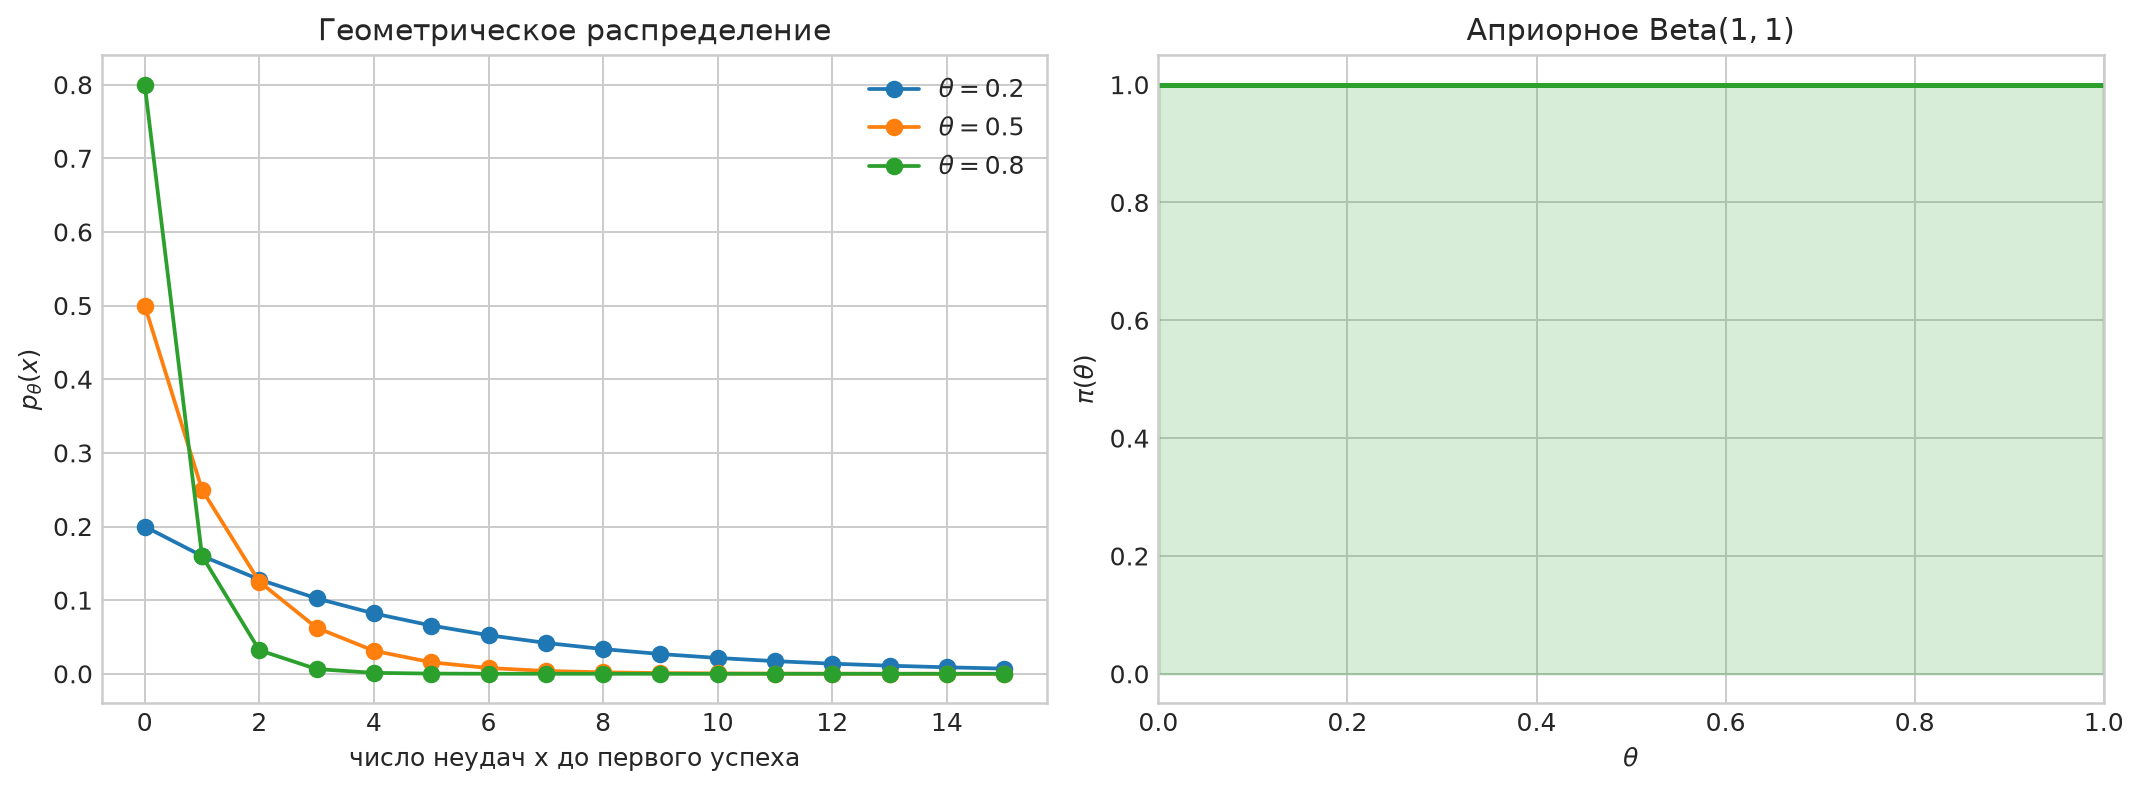

In [2]:
image = save_distribution_plot(
    THETA_VALUES,
    A,
    B,
    OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Оценка максимального правдоподобия

Для независимой выборки $X_1,\ldots,X_n$ обозначим

$$S=\sum_{i=1}^{n}X_i$$

Функция правдоподобия равна

$$L(\theta;x_1,\ldots,x_n)
=\prod_{i=1}^{n}\theta(1-\theta)^{x_i}
=\theta^n(1-\theta)^S$$

Логарифм правдоподобия имеет вид

$$\ell(\theta)=n\ln\theta+S\ln(1-\theta)$$

Найдём первую производную:

$$\ell'(\theta)=\frac n\theta-\frac S{1-\theta}$$

При $S>0$ приравниваем её к нулю:

$$\frac n\theta=\frac S{1-\theta}$$

$$n(1-\theta)=S\theta$$

$$n=(n+S)\theta$$

$$\widehat\theta_{\mathrm{MLE}}=\frac n{n+S}$$

Вторая производная отрицательна:

$$\ell''(\theta)
=-\frac n{\theta^2}-\frac S{(1-\theta)^2}<0$$

Поэтому найденная точка действительно даёт максимум. Если $S=0$, правдоподобие равно $\theta^n$ и возрастает до правой границы. В расширенном пространстве параметров $[0,1]$ оценка равна 1. Таким образом, одна формула охватывает оба случая:

$$\boxed{\widehat\theta_{\mathrm{MLE}}=\frac n{n+S}}$$

Через выборочное среднее её можно записать как

$$\widehat\theta_{\mathrm{MLE}}=\frac1{1+\overline X}$$

In [3]:
demo_total_failures = np.array([DEMO_SUM])
demo_mle = find_mle(demo_total_failures, DEMO_N)[0]

print(f"При n = {DEMO_N} и S = {DEMO_SUM}:")
print(f"MLE = {demo_mle:.6f}")

При n = 10 и S = 20:
MLE = 0.333333


## Апостериорное распределение

По формуле Байеса апостериорная плотность пропорциональна произведению правдоподобия и априорной плотности:

$$\pi(\theta\mid x)
\propto L(\theta;x)\pi(\theta)$$

Подставляем найденные выражения:

$$\pi(\theta\mid x)
\propto
\theta^n(1-\theta)^S
\theta^{a-1}(1-\theta)^{b-1}$$

$$\pi(\theta\mid x)
\propto
\theta^{a+n-1}(1-\theta)^{b+S-1}$$

Это ядро плотности бета-распределения. После нормировки получаем

$$\pi(\theta\mid x)
=\frac{\theta^{a+n-1}(1-\theta)^{b+S-1}}
{B(a+n,b+S)}$$

$$\boxed{\theta\mid X_1,\ldots,X_n
\sim\operatorname{Beta}(a+n,b+S)}$$

Таким образом, семейство бета-распределений является сопряжённым для выбранной параметризации геометрического распределения. Вся информация выборки, необходимая для апостериорного распределения, содержится в достаточной статистике $S$.

Чтобы наглядно увидеть обновление, на следующем графике берутся типичные значения

$$S\approx n\frac{1-\theta}{\theta}$$

При росте $n$ апостериорная плотность всё сильнее концентрируется около истинного параметра.

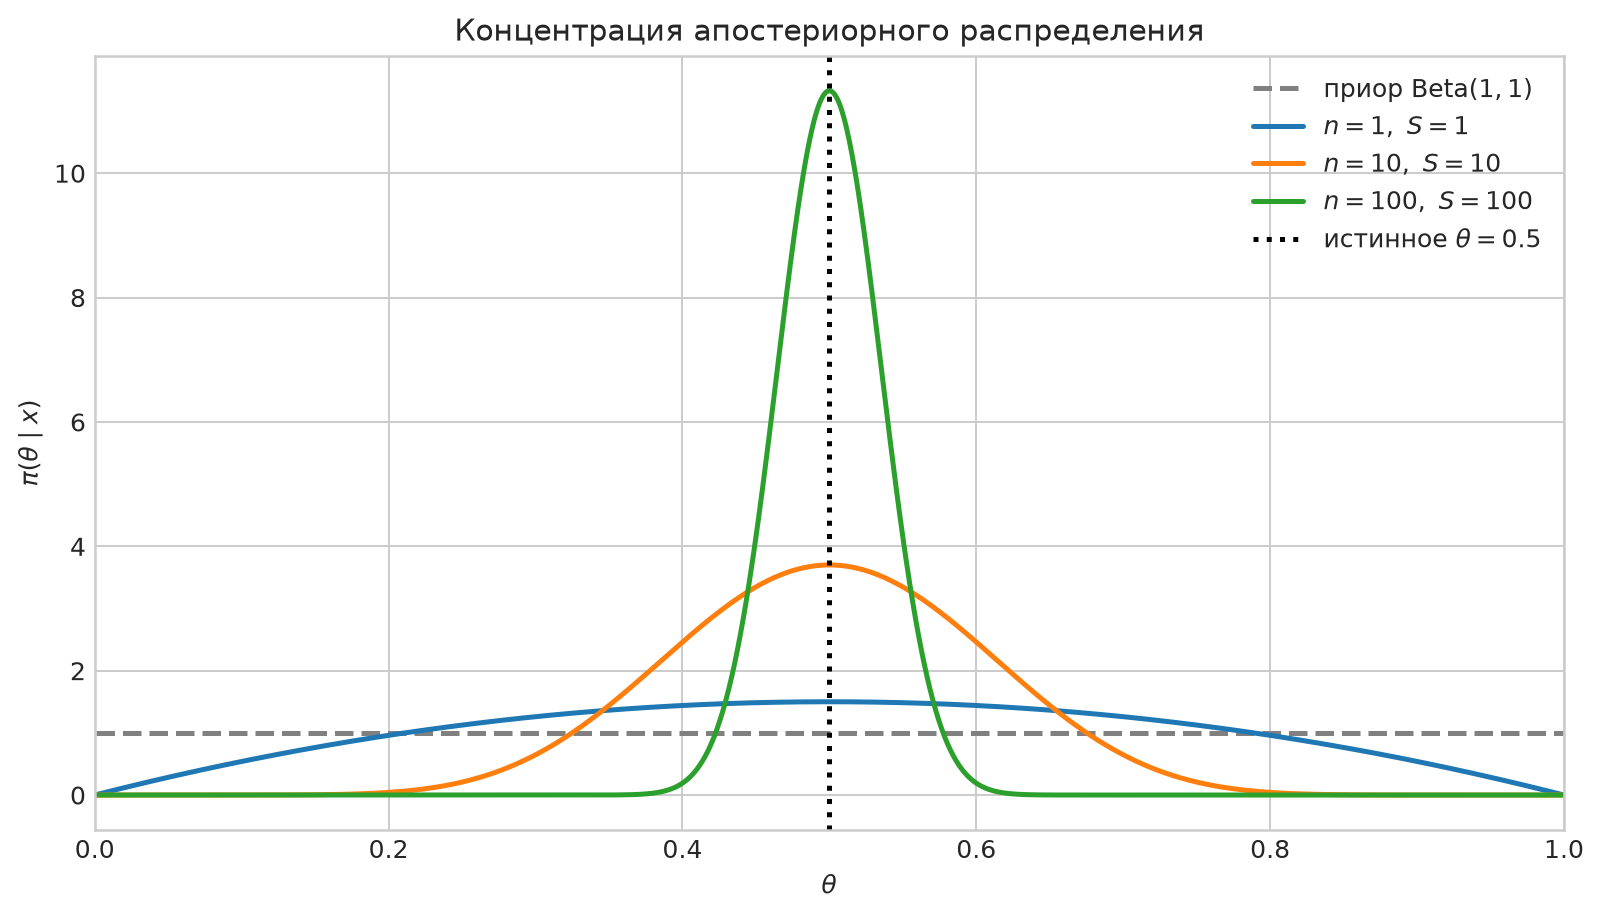

In [4]:
image = save_posterior_plot(
    theta=0.5,
    sample_sizes=POSTERIOR_N,
    a=A,
    b=B,
    output_dir=OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Байесовская оценка при квадратичной потере

Квадратичная функция потерь равна

$$L_2(d,\theta)=(d-\theta)^2$$

После наблюдения выборки выбирается такое решение $d$, которое минимизирует апостериорный риск

$$\rho_2(d\mid x)
=\mathbb E[(d-\theta)^2\mid x]$$

Обозначим апостериорное математическое ожидание через

$$m=\mathbb E[\theta\mid x]$$

Тогда

$$d-\theta=(d-m)+(m-\theta)$$

$$\begin{aligned}
\rho_2(d\mid x)
&=\mathbb E[((d-m)+(m-\theta))^2\mid x]\\
&=(d-m)^2
+2(d-m)\mathbb E[m-\theta\mid x]
+\mathbb E[(m-\theta)^2\mid x]
\end{aligned}$$

Так как $\mathbb E[m-\theta\mid x]=0$, получаем

$$\rho_2(d\mid x)
=(d-m)^2+\operatorname{Var}(\theta\mid x)$$

Второе слагаемое от $d$ не зависит, а первое минимально при $d=m$. Следовательно, байесовская оценка при квадратичной потере равна апостериорному среднему. Для распределения $\operatorname{Beta}(\alpha,\beta)$ среднее равно $\alpha/(\alpha+\beta)$, поэтому

$$\boxed{
\widehat\theta_{L_2}
=\mathbb E[\theta\mid x]
=\frac{a+n}{a+b+n+S}
}$$

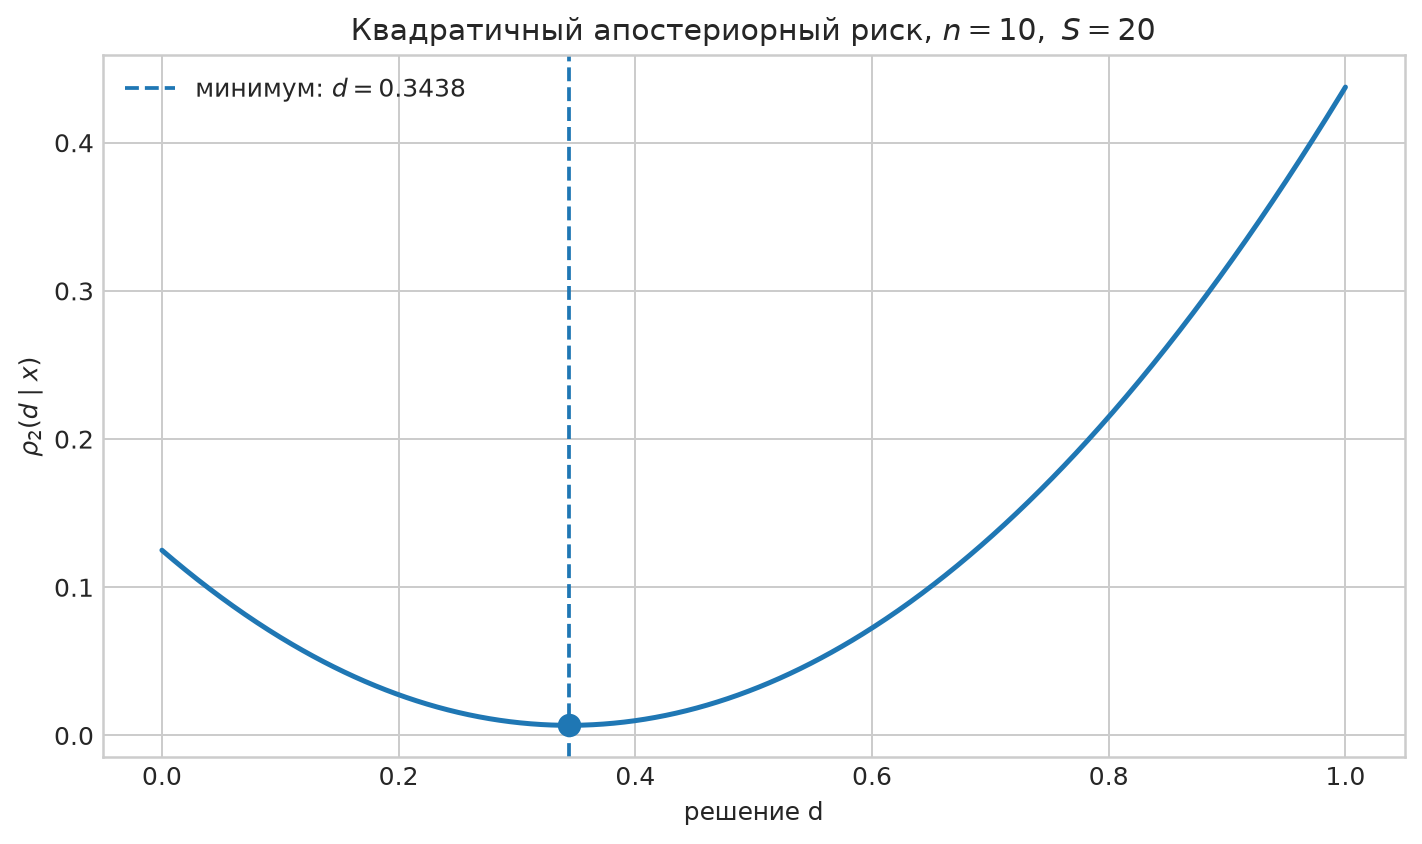

In [5]:
image = save_squared_loss_plot(
    DEMO_N,
    DEMO_SUM,
    A,
    B,
    OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Байесовская оценка при абсолютной потере

Абсолютная функция потерь равна

$$L_1(d,\theta)=|d-\theta|$$

Апостериорный риск можно разбить на два интеграла:

$$\rho_1(d\mid x)
=\int_0^d(d-\theta)\pi(\theta\mid x)\,d\theta
+\int_d^1(\theta-d)\pi(\theta\mid x)\,d\theta$$

Обозначим апостериорную функцию распределения через $F(\theta\mid x)$. Дифференцируем риск по $d$. Граничные слагаемые равны нулю, потому что при $\theta=d$ множитель $|d-\theta|$ обращается в ноль:

$$\frac{\partial}{\partial d}\rho_1(d\mid x)
=\int_0^d\pi(\theta\mid x)\,d\theta
-\int_d^1\pi(\theta\mid x)\,d\theta$$

$$\frac{\partial}{\partial d}\rho_1(d\mid x)
=F(d\mid x)-(1-F(d\mid x))$$

$$\frac{\partial}{\partial d}\rho_1(d\mid x)
=2F(d\mid x)-1$$

Минимум достигается при

$$F(d\mid x)=\frac12$$

Следовательно, байесовская оценка при абсолютной потере равна апостериорной медиане:

$$\boxed{
\widehat\theta_{L_1}
=F^{-1}_{\operatorname{Beta}(a+n,b+S)}\left(\frac12\right)
}$$

Для медианы бета-распределения в общем случае нет простой элементарной формулы, поэтому в эксперименте она вычисляется квантильной функцией `scipy.stats.beta.ppf`.

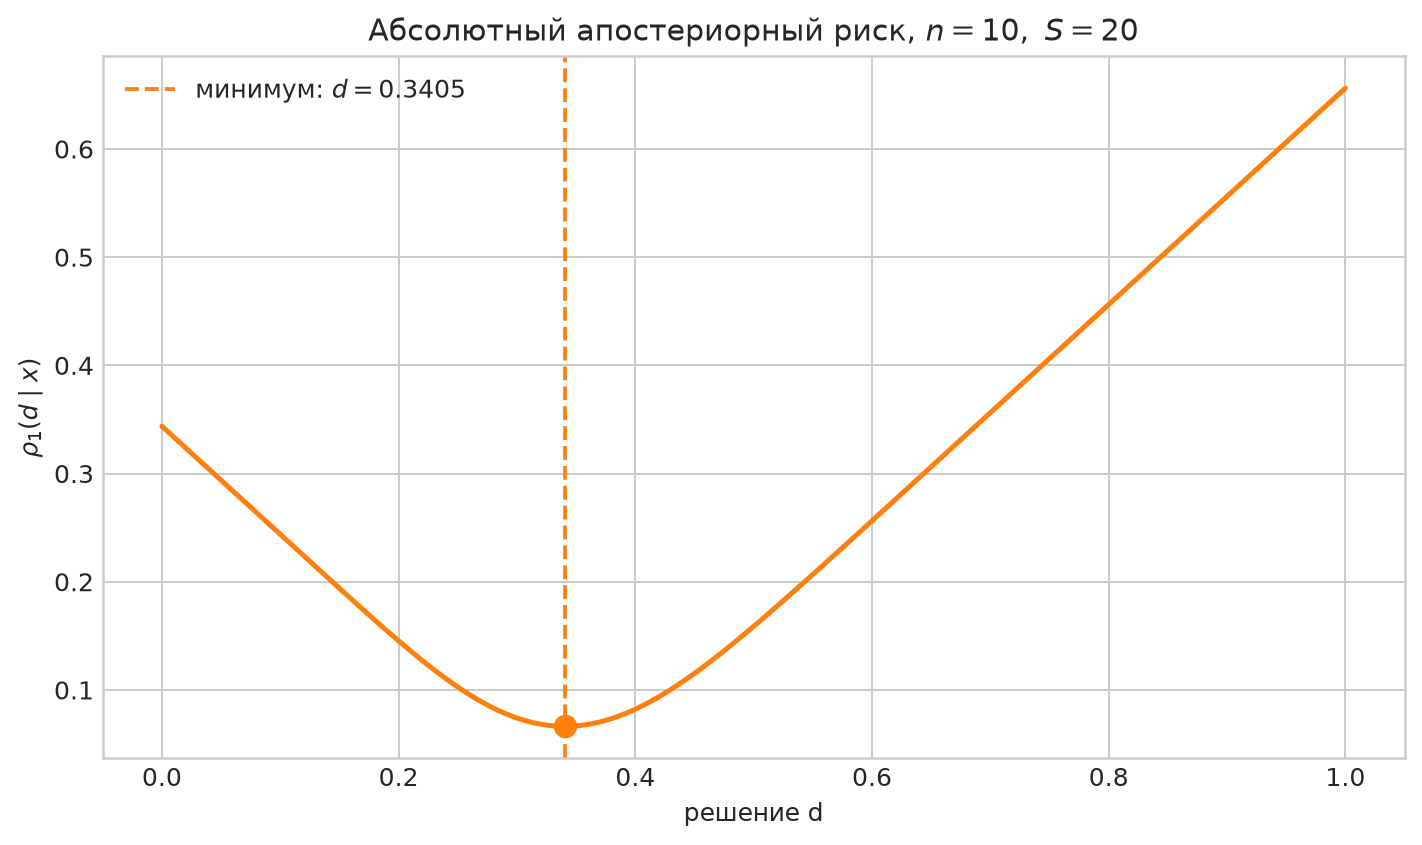

In [6]:
image = save_absolute_loss_plot(
    DEMO_N,
    DEMO_SUM,
    A,
    B,
    OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Байесовская оценка при 0–1 потере

Для дискретного параметра 0–1 потеря задаётся формулой

$$L_{0-1}(d,\theta)=\mathbb{1}(d\ne\theta)$$

Но в нашей задаче параметр непрерывен. Апостериорное распределение также непрерывно, поэтому для любого фиксированного решения $d$

$$\mathbb P(\theta=d\mid x)=0$$

$$\rho_{0-1}(d\mid x)
=\mathbb P(\theta\ne d\mid x)
=1$$

Буквальная 0–1 потеря не различает решения: любое $d$ является байесовским. Именно поэтому в условии сделано замечание о непрерывности.

Содержательная непрерывная версия вводит малый допуск $\varepsilon>0$:

$$L_{0-1,\varepsilon}(d,\theta)
=\mathbb{1}(|d-\theta|>\varepsilon)$$

Её апостериорный риск равен

$$\rho_{0-1,\varepsilon}(d\mid x)
=1-\int_{d-\varepsilon}^{d+\varepsilon}
\pi(u\mid x)\,du$$

С учётом границ $(0,1)$ пределы интегрирования обрезаются до этого интервала. Для малого $\varepsilon$

$$\int_{d-\varepsilon}^{d+\varepsilon}
\pi(u\mid x)\,du
=2\varepsilon\pi(d\mid x)+o(\varepsilon)$$

Поэтому при $\varepsilon\to0$ минимизация риска сводится к максимизации апостериорной плотности. Предельная байесовская оценка является апостериорной модой, то есть MAP-оценкой.

Для $\operatorname{Beta}(\alpha,\beta)$ при $\alpha>1$ и $\beta>1$

$$\operatorname{mode}
=\frac{\alpha-1}{\alpha+\beta-2}$$

Подставляем $\alpha=a+n$ и $\beta=b+S$:

$$\boxed{
\widehat\theta_{0-1}
=\widehat\theta_{\mathrm{MAP}}
=\frac{a+n-1}{a+b+n+S-2}
}$$

Если $\alpha\leq1<\beta$, мода находится в точке 0. Если $\beta\leq1<\alpha$, мода находится в точке 1. При $\alpha<1$ и $\beta<1$ обе границы являются модами.

На графике верхняя часть показывает MAP как максимум плотности. Нижняя часть показывает точный риск при конечном $\varepsilon=0.05$. Его минимум может немного отличаться от MAP, потому что при конечном допуске максимизируется масса целого интервала, а MAP получается именно в пределе $\varepsilon\to0$.

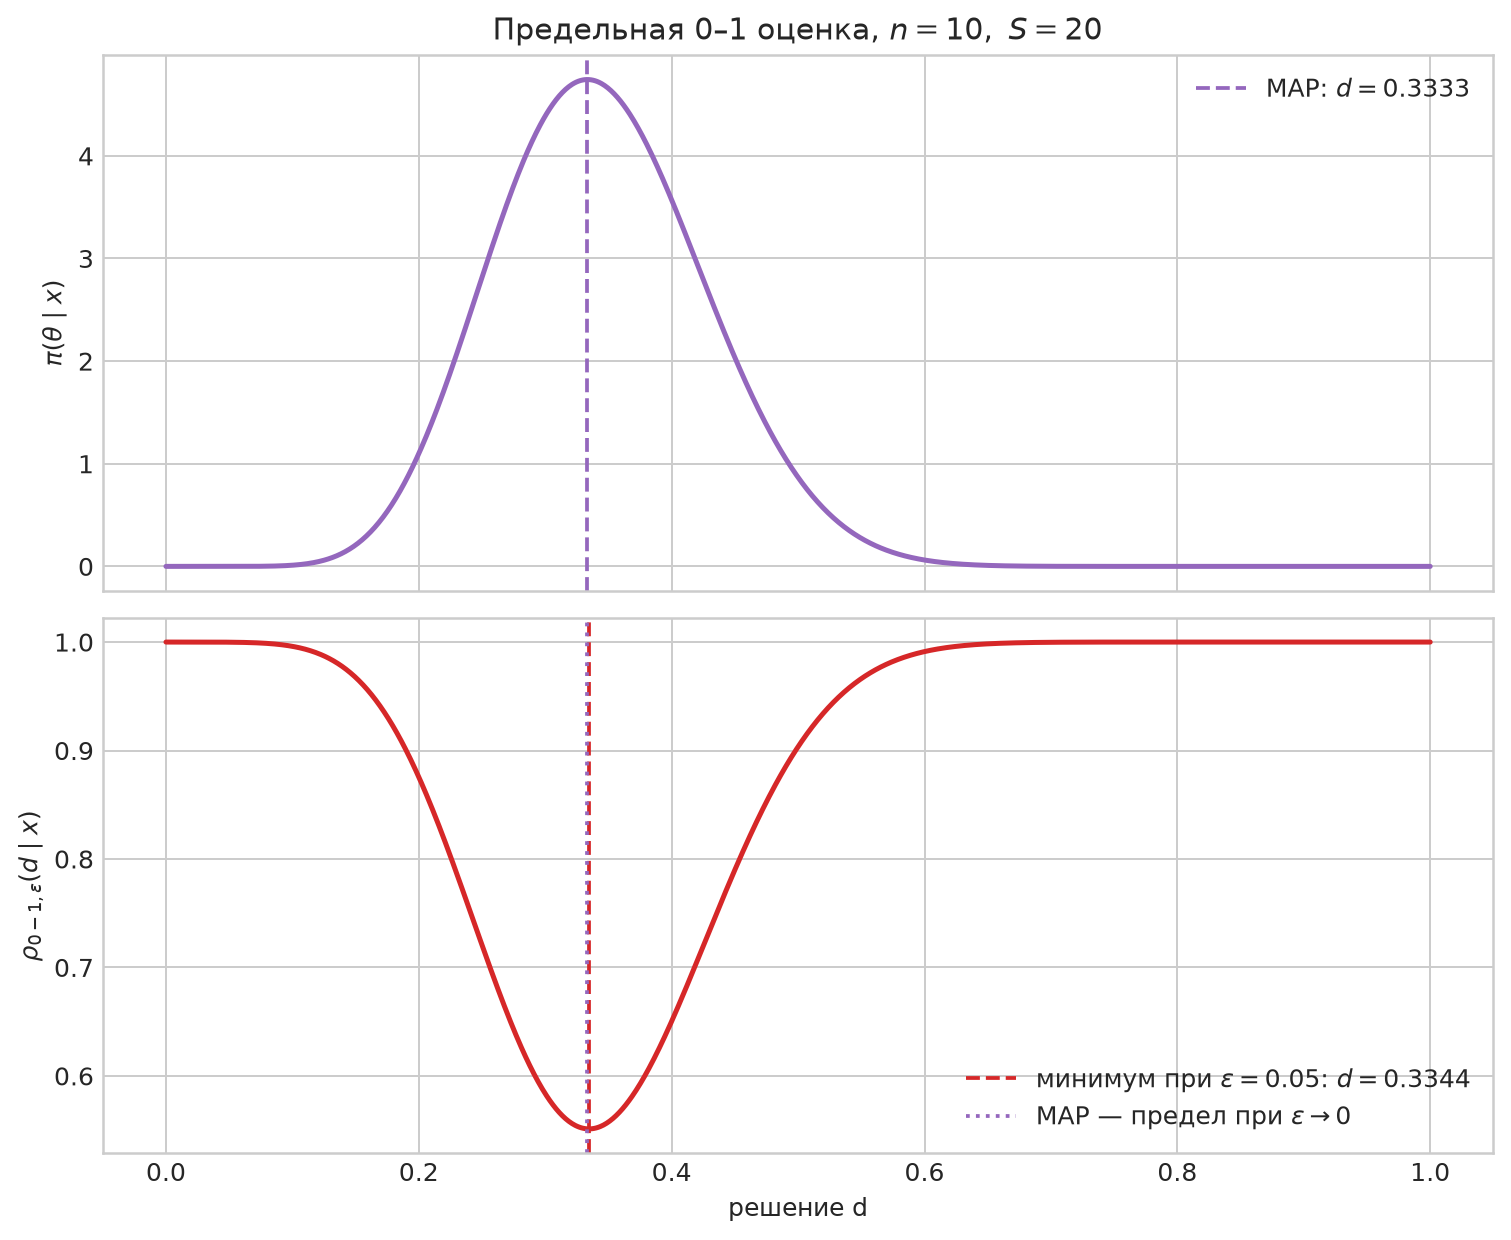

In [7]:
image = save_zero_one_loss_plot(
    DEMO_N,
    DEMO_SUM,
    A,
    B,
    EPSILON,
    OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Сравнение формул при $a=b=1$

Для заданного в эксперименте равномерного априорного распределения три байесовские оценки принимают вид

$$\widehat\theta_{L_2}
=\frac{n+1}{n+S+2}$$

$$\widehat\theta_{L_1}
=F^{-1}_{\operatorname{Beta}(n+1,S+1)}\left(\frac12\right)$$

$$\widehat\theta_{0-1}
=\widehat\theta_{\mathrm{MAP}}
=\frac n{n+S}
=\widehat\theta_{\mathrm{MLE}}$$

Последнее равенство выполняется и при $S=0$: и MAP, и MLE находятся на правой границе 1.

Разность между апостериорным средним и MLE можно вычислить точно:

$$\begin{aligned}
\widehat\theta_{L_2}-\widehat\theta_{\mathrm{MLE}}
&=\frac{n+1}{n+S+2}-\frac n{n+S}\\
&=\frac{S-n}{(n+S+2)(n+S)}
\end{aligned}$$

Если $S>n$, то MLE меньше $1/2$, а байесовская оценка сдвигается вверх. Если $S<n$, то MLE больше $1/2$, а байесовская оценка сдвигается вниз. Это влияние равномерного приора: апостериорное среднее немного стягивается к априорному среднему $1/2$.

При росте выборки по закону больших чисел

$$\frac Sn=\overline X\xrightarrow{p}\mathbb EX
=\frac{1-\theta}{\theta}$$

Поэтому

$$\widehat\theta_{\mathrm{MLE}}
=\frac1{1+S/n}
\xrightarrow{p}\theta$$

Параметры апостериорного распределения растут пропорционально $n$, а само распределение концентрируется около $\theta$. Поэтому его среднее, медиана и мода также сходятся к $\theta$, а различия между всеми четырьмя оценками исчезают.

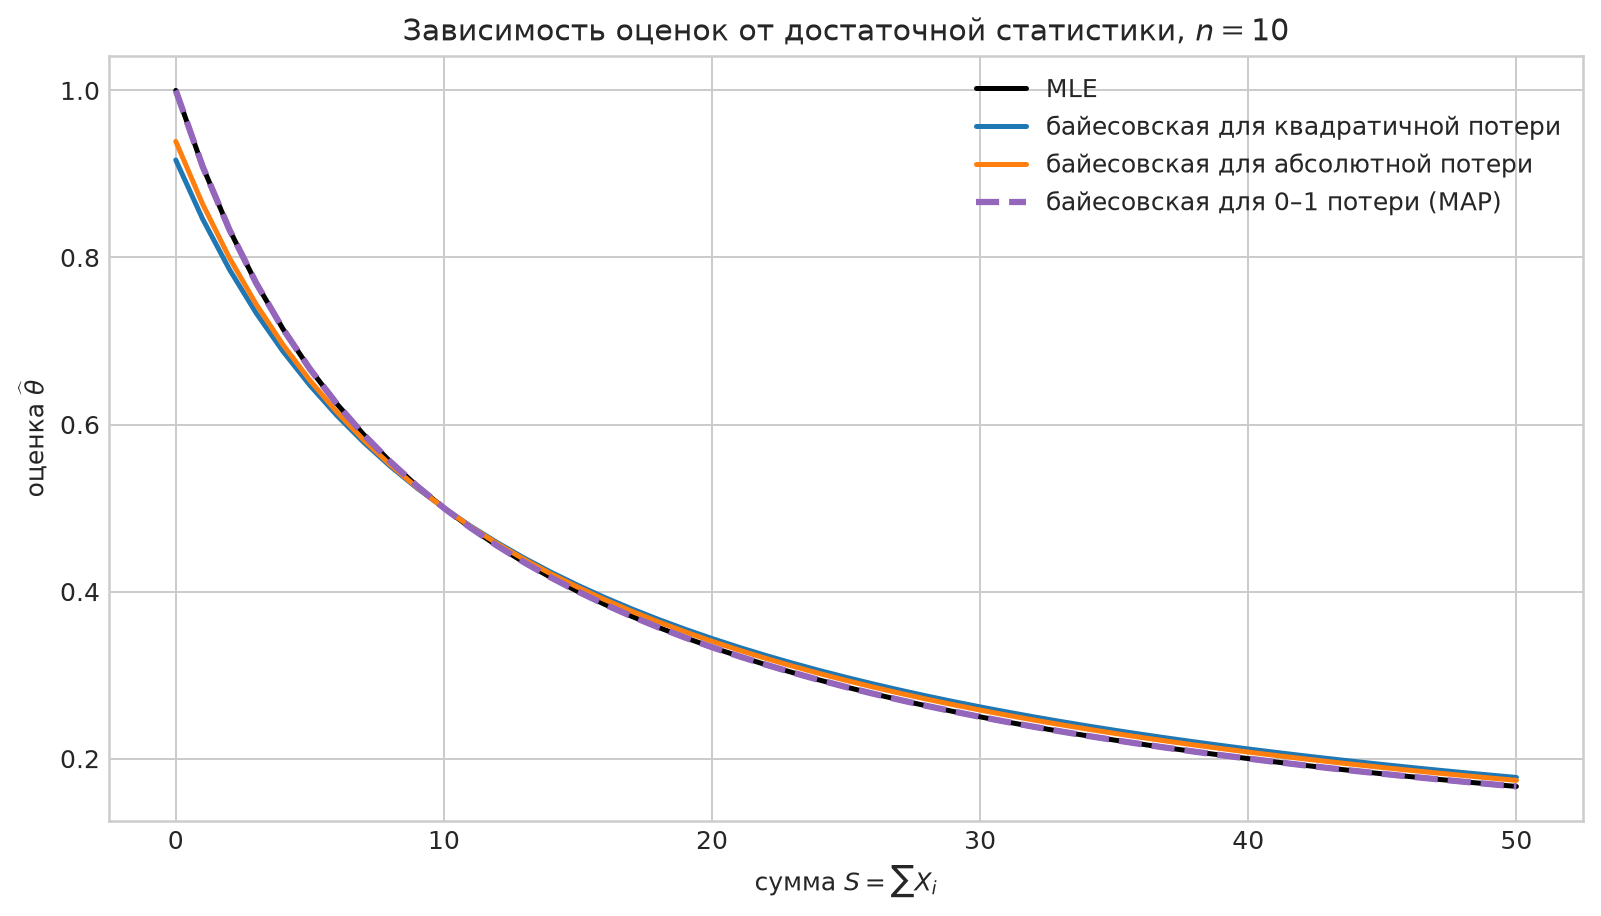

In [8]:
image = save_estimator_formula_plot(
    n=DEMO_N,
    max_total_failures=50,
    a=A,
    b=B,
    output_dir=OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Минимаксность

Частотный риск оценки $\delta$ определяется как

$$R(\theta,\delta)
=\mathbb E_\theta L(\delta(X),\theta)$$

Минимаксная оценка минимизирует наибольший риск:

$$\delta^*
\in\operatorname*{arg\,min}_{\delta}
\sup_{\theta\in(0,1)}R(\theta,\delta)$$

Сам факт, что оценка является байесовской, ещё не доказывает её минимаксность. Например, достаточным условием было бы равенство байесовского риска максимальному частотному риску или постоянство функции риска байесовской оценки.

### Буквальная 0–1 потеря

Пространство выборок $\{0,1,2,\ldots\}^n$ счётно. Поэтому множество значений любой нерандомизированной оценки $\delta(X)$ также не более чем счётно. Пространство параметров $(0,1)$ несчётно, значит, существует такое $\theta_0$, которое оценка никогда не принимает:

$$\theta_0\notin\{\delta(x):x\in\{0,1,2,\ldots\}^n\}$$

Для этого параметра

$$R(\theta_0,\delta)
=\mathbb P_{\theta_0}(\delta(X)\ne\theta_0)
=1$$

Поскольку 0–1 риск не может быть больше 1, для любой оценки

$$\sup_{\theta\in(0,1)}R(\theta,\delta)=1$$

Следовательно, при буквальной 0–1 потере **любая оценка минимаксна**.

При любом собственном бета-приоре $a,b>0$ апостериорное распределение непрерывно. Поэтому апостериорный 0–1 риск любого решения также равен 1 и любая оценка является байесовской. Получаем строгий ответ для буквальной постановки:

$$\boxed{a,b>0:\ \text{любая байесовская оценка одновременно минимаксна}}$$

Этот результат математически верен, но неинформативен. Поэтому на практике рассматривают $\varepsilon$-версию потери и её предел — MAP.

### Когда MAP совпадает с MLE

Для внутренних мод требуется равенство

$$\frac{a+n-1}{a+b+n+S-2}
=\frac n{n+S}$$

Если оно должно выполняться при всех $S$, сравнение коэффициентов при $S$ даёт $a=1$. После подстановки $a=1$ сравнение свободных частей даёт $b=1$. Следовательно

$$\boxed{\widehat\theta_{\mathrm{MAP}}
=\widehat\theta_{\mathrm{MLE}}\ \text{для всех выборок}
\iff a=b=1}$$

Совпадение MAP с MLE само по себе не доказывает минимаксность относительно конечной $\varepsilon$-потери. Для неё необходимо отдельно исследовать максимальный риск.

Для сравнения, апостериорное среднее совпало бы с MLE при всех $S$ только в несобственном пределе $a=b=0$:

$$\frac{a+n}{a+b+n+S}=\frac n{n+S}
\ \text{для всех }S
\iff a=b=0$$

Этот случай не входит в условие $a,b>0$.

In [9]:
check_sums = np.arange(101)
check_estimates = find_estimates(
    check_sums,
    DEMO_N,
    A,
    B,
)
max_map_mle_difference = np.max(
    np.abs(
        check_estimates["zero_one"]
        - check_estimates["mle"]
    )
)

print(
    "Максимальная разность между MAP и MLE "
    f"при a = b = 1: {max_map_mle_difference:.1f}"
)

Максимальная разность между MAP и MLE при a = b = 1: 0.0


## Вычислительный эксперимент

Для каждой пары $(\theta,n)$ генерируем $M=5000$ независимых значений

$$S\sim\operatorname{NegBin}(n,\theta)$$

На одном и том же значении $S$ вычисляются MLE и все три байесовские оценки. Благодаря этому сравнение не искажается различиями между случайно сгенерированными наборами данных.

Для каждой оценки вычисляются

$$\widehat{\operatorname{Bias}}
=\frac1M\sum_{j=1}^{M}(\widehat\theta_j-\theta)$$

$$\widehat{\operatorname{MSE}}
=\frac1M\sum_{j=1}^{M}(\widehat\theta_j-\theta)^2$$

$$\widehat{\operatorname{MAE}}
=\frac1M\sum_{j=1}^{M}|\widehat\theta_j-\theta|$$

$$\widehat R_{0-1,\varepsilon}
=\frac1M\sum_{j=1}^{M}
\mathbb{1}(|\widehat\theta_j-\theta|>\varepsilon)$$

Последняя величина равна доле оценок, вышедших за допустимую полосу $[\theta-\varepsilon,\theta+\varepsilon]$.

In [10]:
experiment = run_bayes_experiment(
    THETA_VALUES,
    N,
    M,
    A,
    B,
    EPSILON,
    RNG,
)

print(
    f"Готово: {len(THETA_VALUES)} значения theta, "
    f"{len(N)} объёмов выборки и {M} повторений"
)

Готово: 3 значения theta, 10 объёмов выборки и 5000 повторений


## Сравнение при квадратичной потере

Для квадратичной потери сравниваем апостериорное среднее $\widehat\theta_{L_2}$ с MLE по выборочной MSE. Также отдельно смотрим смещение и распределение отдельных оценок.

На графике разности рисков откладывается

$$\Delta_{\mathrm{MSE}}
=\widehat{\operatorname{MSE}}(\widehat\theta_{L_2})
-\widehat{\operatorname{MSE}}(\widehat\theta_{\mathrm{MLE}})$$

Если $\Delta_{\mathrm{MSE}}<0$, байесовская оценка лучше на выбранном истинном $\theta$ в данном эксперименте. Если $\Delta_{\mathrm{MSE}}>0$, лучше MLE. Байесовская оптимальность относится к среднему апостериорному риску, поэтому она не означает обязательного выигрыша при каждом фиксированном $\theta$.

theta = 0.2
n =    1: ΔMSE = -0.07728965
n =    2: ΔMSE = -0.01504216
n =    5: ΔMSE = +0.00071667
n =   10: ΔMSE = +0.00047337
n =   20: ΔMSE = +0.00013825
n =   50: ΔMSE = +0.00002304
n =  100: ΔMSE = +0.00000665
n =  200: ΔMSE = +0.00000092
n =  500: ΔMSE = +0.00000021
n = 1000: ΔMSE = +0.00000004

theta = 0.5
n =    1: ΔMSE = -0.11698905
n =    2: ΔMSE = -0.05531549
n =    5: ΔMSE = -0.01197858
n =   10: ΔMSE = -0.00303911
n =   20: ΔMSE = -0.00068502
n =   50: ΔMSE = -0.00010030
n =  100: ΔMSE = -0.00002555
n =  200: ΔMSE = -0.00000627
n =  500: ΔMSE = -0.00000104
n = 1000: ΔMSE = -0.00000024

theta = 0.8
n =    1: ΔMSE = -0.02036452
n =    2: ΔMSE = -0.01892408
n =    5: ΔMSE = -0.00811160
n =   10: ΔMSE = -0.00302290
n =   20: ΔMSE = -0.00105497
n =   50: ΔMSE = -0.00017998
n =  100: ΔMSE = -0.00004073
n =  200: ΔMSE = -0.00001282
n =  500: ΔMSE = -0.00000208
n = 1000: ΔMSE = -0.00000064



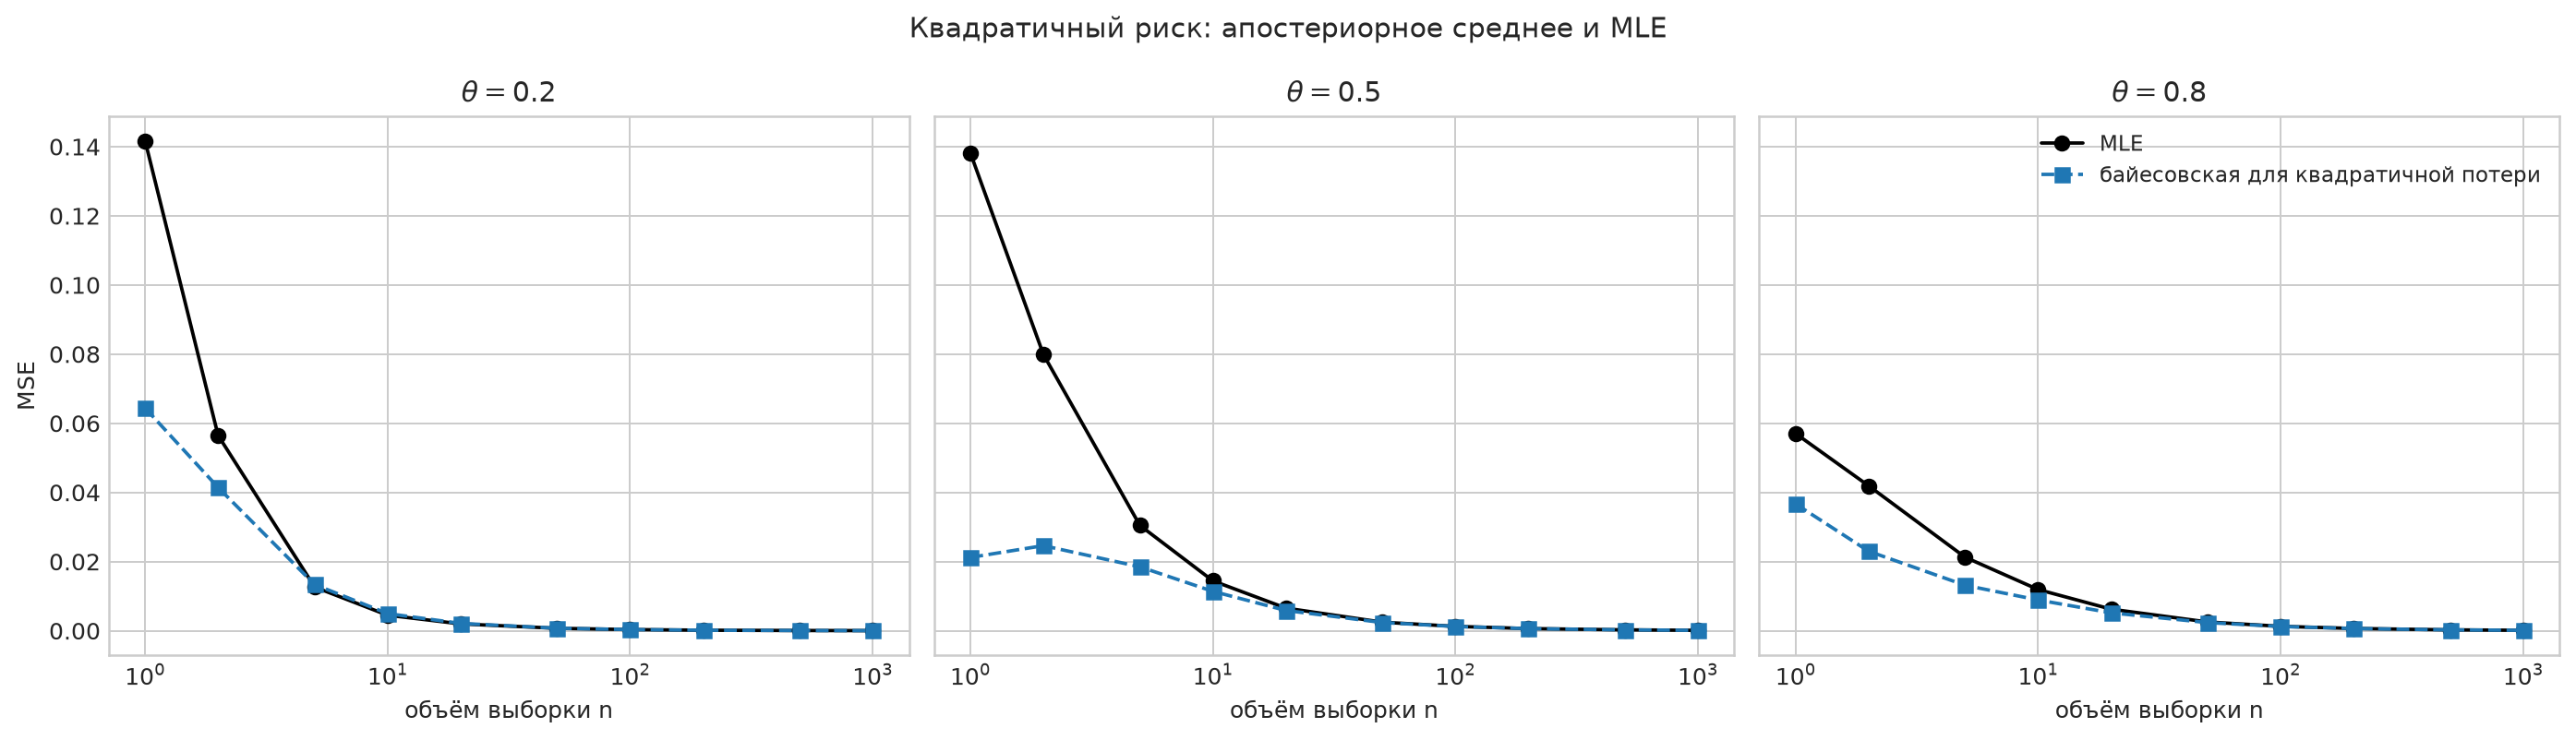

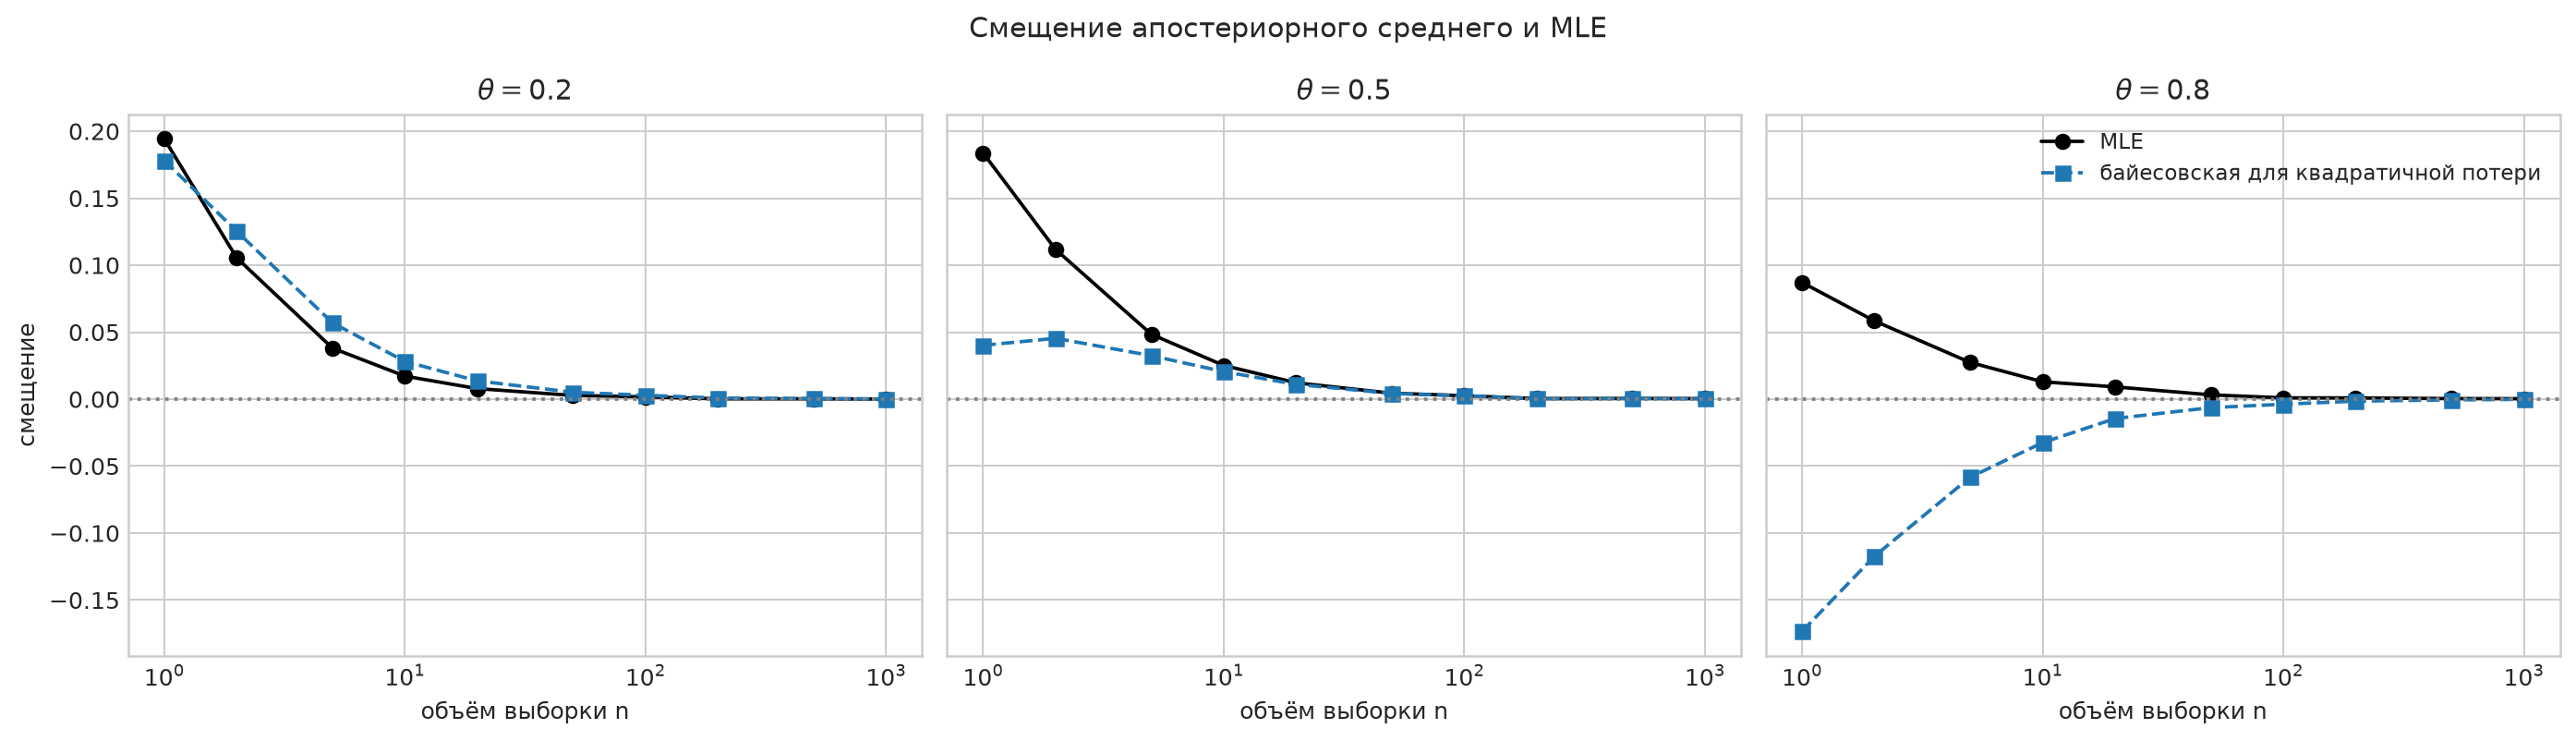

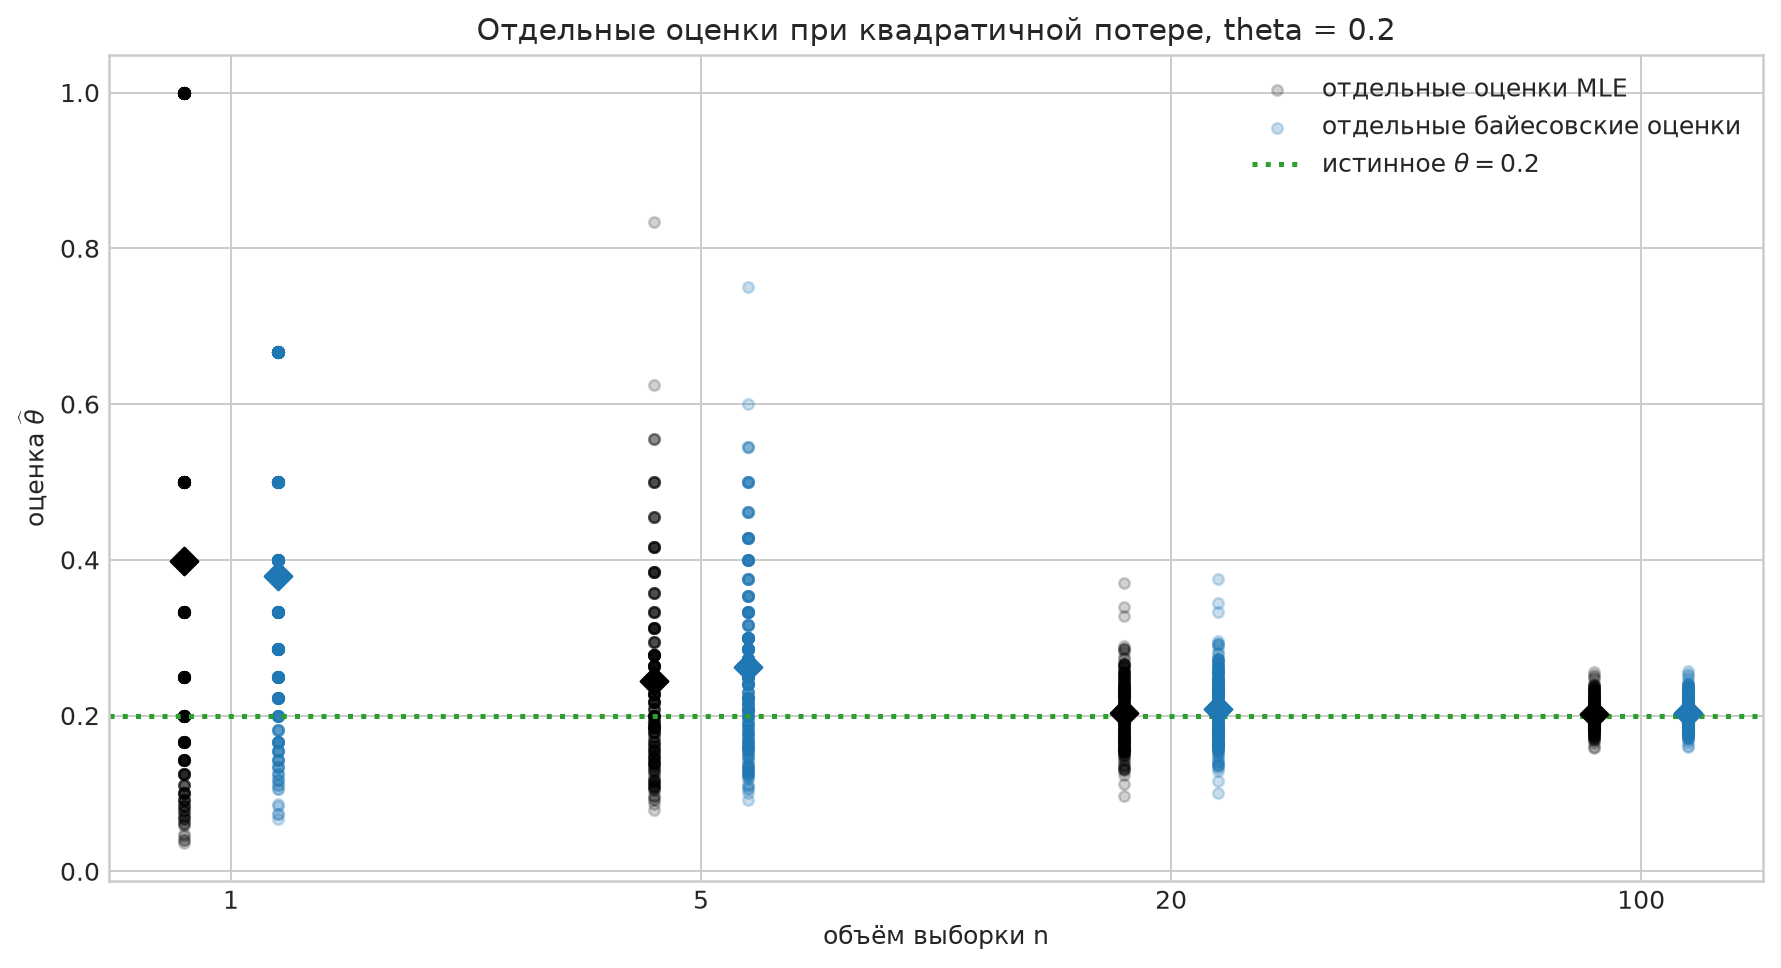

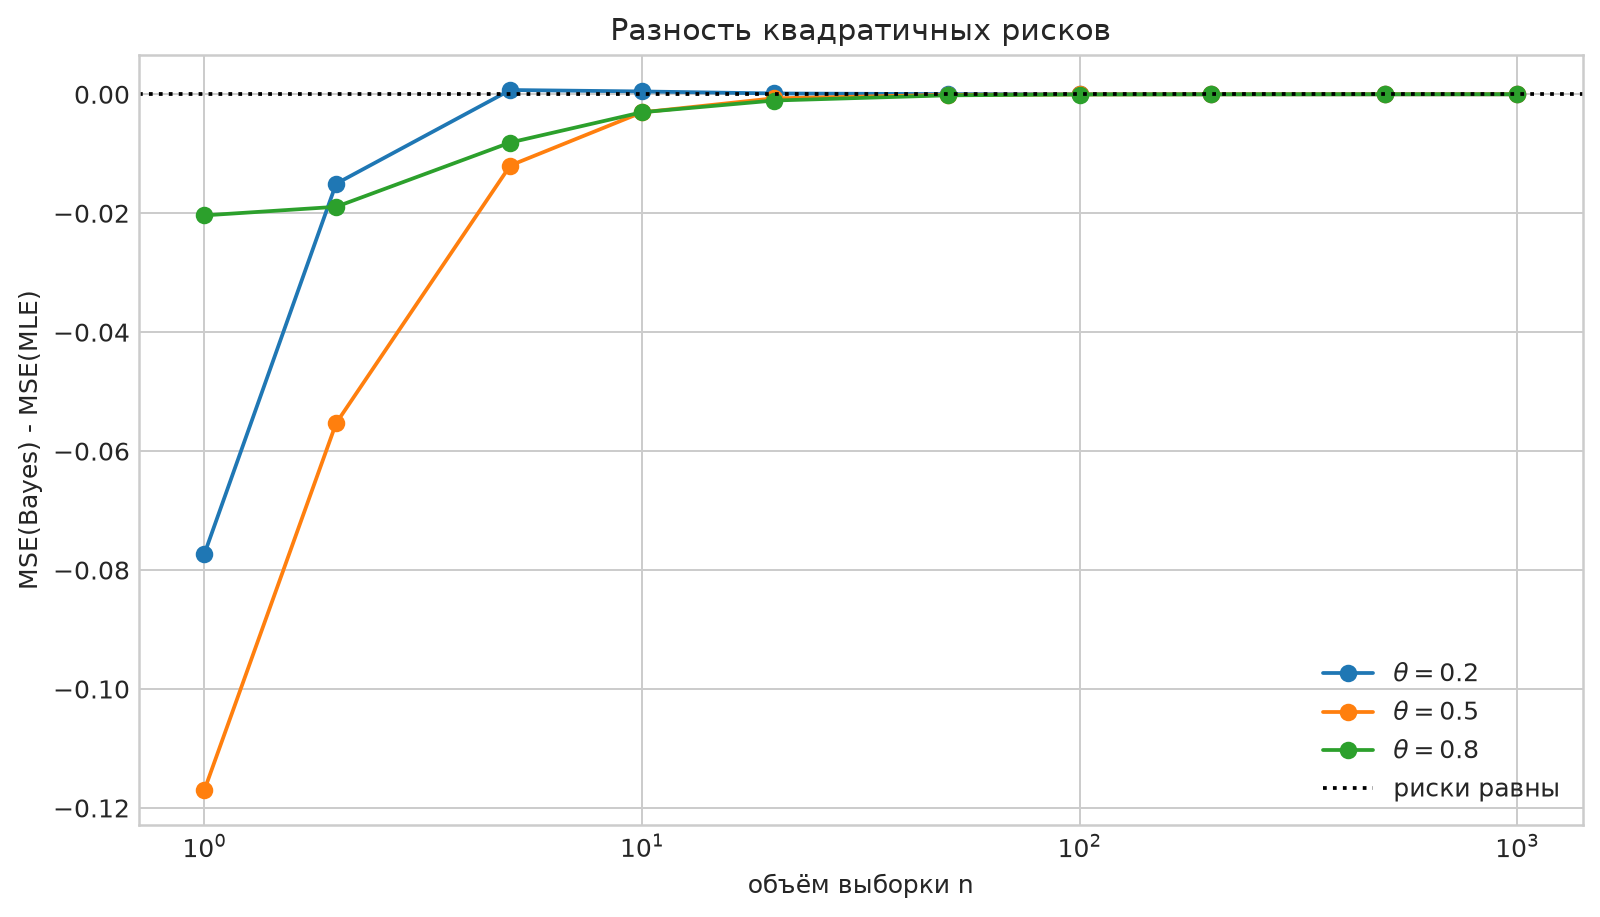

In [11]:
for theta in THETA_VALUES:
    print(f"theta = {theta:g}")
    for n in N:
        metrics = experiment["results"][float(theta)][int(n)]["metrics"]
        delta = metrics["squared"]["mse"] - metrics["mle"]["mse"]
        print(f"n = {n:4d}: ΔMSE = {delta:+.8f}")
    print()

images = [
    save_metric_plot(
        experiment,
        "squared",
        "mse",
        "MSE",
        "Квадратичный риск: апостериорное среднее и MLE",
        "mse.png",
        OUTPUT_DIR,
    ),
    save_bias_plot(
        experiment,
        "squared",
        "Смещение апостериорного среднего и MLE",
        "squared_bias.png",
        OUTPUT_DIR,
    ),
    save_estimate_cloud_plot(
        experiment,
        0.2,
        CLOUD_N,
        "squared",
        "Отдельные оценки при квадратичной потере, theta = 0.2",
        "squared_cloud.png",
        OUTPUT_DIR,
    ),
    save_risk_difference_plot(
        experiment,
        "squared",
        "mse",
        "MSE(Bayes) - MSE(MLE)",
        "Разность квадратичных рисков",
        "squared_risk_difference.png",
        OUTPUT_DIR,
    ),
]

for image in images:
    display(Image(filename=str(image)))

### Вывод по квадратичной потере

При малых $n$ апостериорное среднее заметно отличается от MLE: равномерный приор стягивает оценку к $1/2$. Поэтому при $\theta=0.2$ и $\theta=0.8$ появляется направленное смещение, но одновременно уменьшается разброс отдельных оценок. При $\theta=0.5$ центр приора совпадает с истинным параметром, поэтому такое стягивание особенно полезно.

В проведённом эксперименте при $\theta=0.2$ байесовская MSE меньше для $n=1$ и $n=2$, а начиная с $n=5$ MLE получает небольшой выигрыш. При $\theta=0.5$ и $\theta=0.8$ апостериорное среднее даёт меньшую MSE на рассмотренных объёмах. Эти результаты относятся к выбранным значениям параметра и не превращают одну оценку в равномерно лучшую для всех $\theta$.

С ростом $n$ влияние двух псевдонаблюдений, внесённых параметрами $a=b=1$, становится малым. Облака оценок сжимаются, MSE обеих оценок стремится к нулю, а разность рисков приближается к нулю.

## Сравнение при абсолютной потере

Для абсолютной потери сравниваем апостериорную медиану $\widehat\theta_{L_1}$ с MLE по выборочной MAE.

На графике разности рисков используется

$$\Delta_{\mathrm{MAE}}
=\widehat{\operatorname{MAE}}(\widehat\theta_{L_1})
-\widehat{\operatorname{MAE}}(\widehat\theta_{\mathrm{MLE}})$$

Отрицательное значение означает меньшую среднюю абсолютную ошибку у апостериорной медианы. Как и в предыдущем разделе, дополнительно показываются смещение и отдельные реализации оценок.

theta = 0.2
n =    1: ΔMAE = -0.05041627
n =    2: ΔMAE = -0.00630568
n =    5: ΔMAE = +0.00239757
n =   10: ΔMAE = +0.00125173
n =   20: ΔMAE = +0.00044399
n =   50: ΔMAE = +0.00013248
n =  100: ΔMAE = +0.00005445
n =  200: ΔMAE = +0.00000567
n =  500: ΔMAE = +0.00000386
n = 1000: ΔMAE = +0.00000006

theta = 0.5
n =    1: ΔMAE = -0.15904023
n =    2: ΔMAE = -0.07344399
n =    5: ΔMAE = -0.01946299
n =   10: ΔMAE = -0.00665893
n =   20: ΔMAE = -0.00219241
n =   50: ΔMAE = -0.00053574
n =  100: ΔMAE = -0.00018988
n =  200: ΔMAE = -0.00006648
n =  500: ΔMAE = -0.00001710
n = 1000: ΔMAE = -0.00000584

theta = 0.8
n =    1: ΔMAE = -0.08704124
n =    2: ΔMAE = -0.11078108
n =    5: ΔMAE = -0.02730316
n =   10: ΔMAE = -0.01529135
n =   20: ΔMAE = -0.00345773
n =   50: ΔMAE = -0.00146744
n =  100: ΔMAE = -0.00023776
n =  200: ΔMAE = -0.00012863
n =  500: ΔMAE = -0.00003641
n = 1000: ΔMAE = -0.00001083



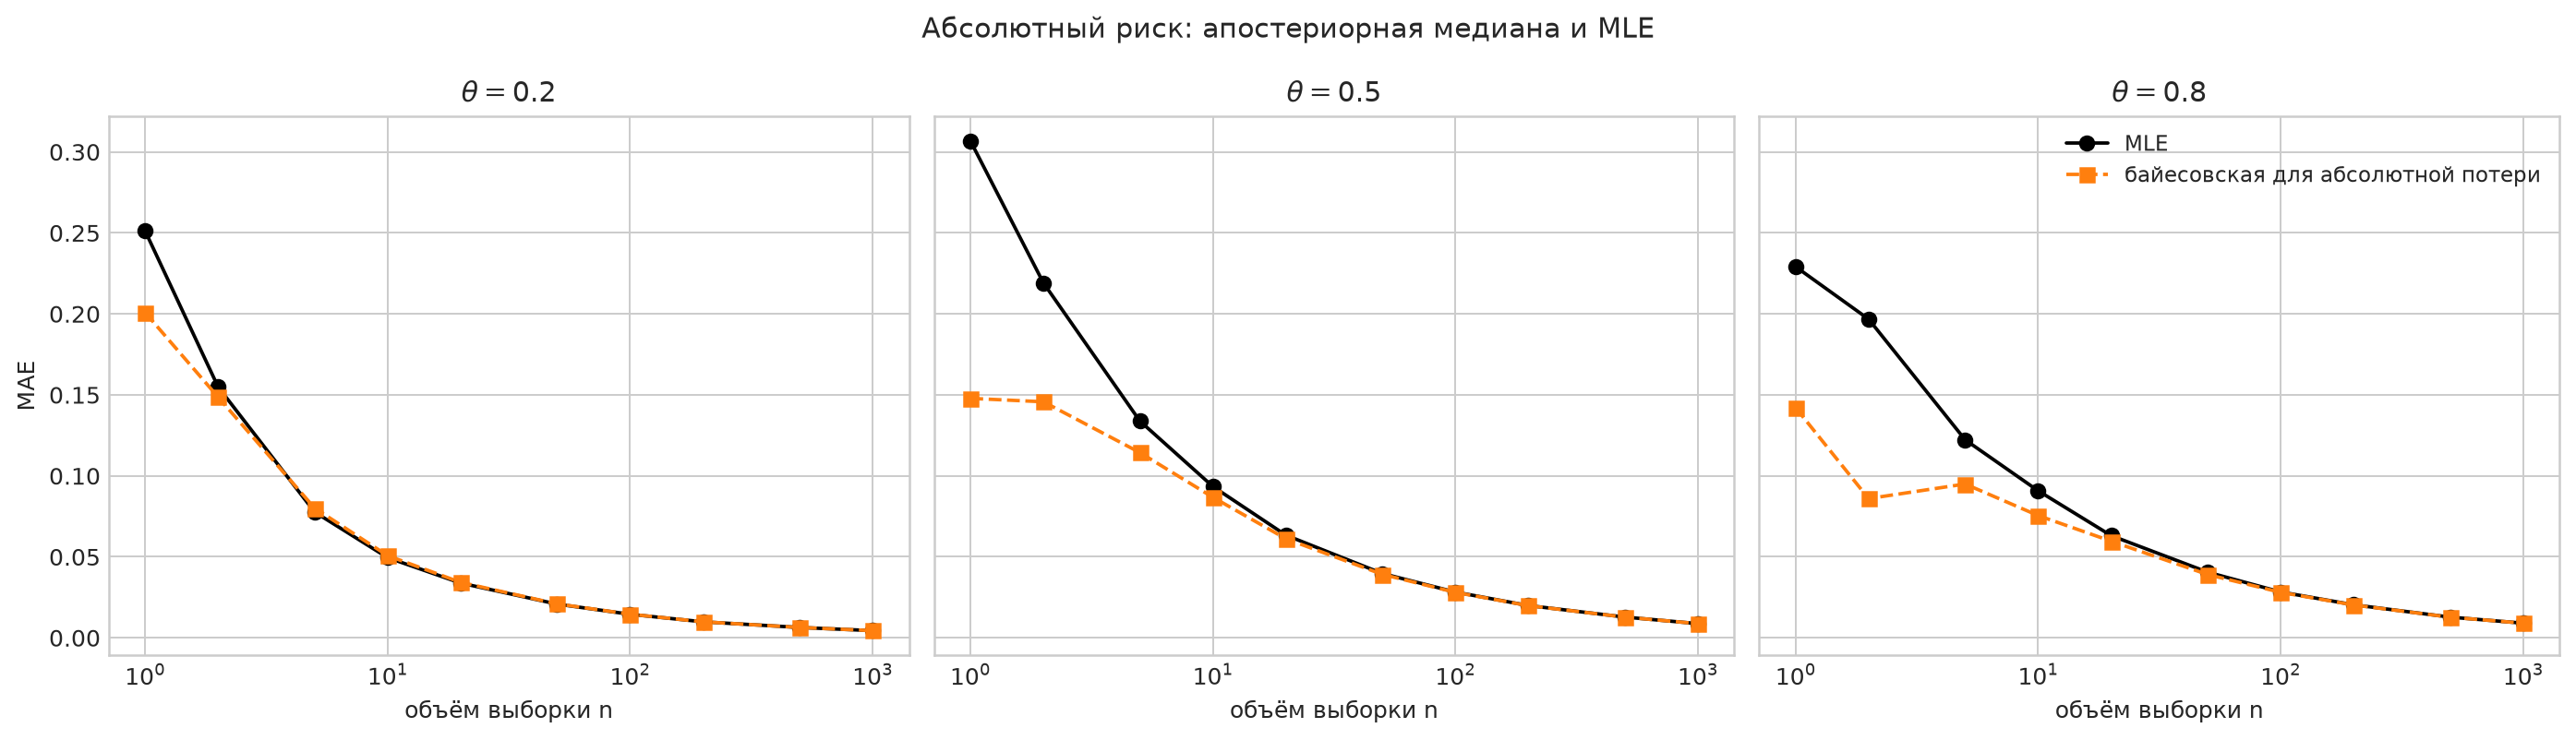

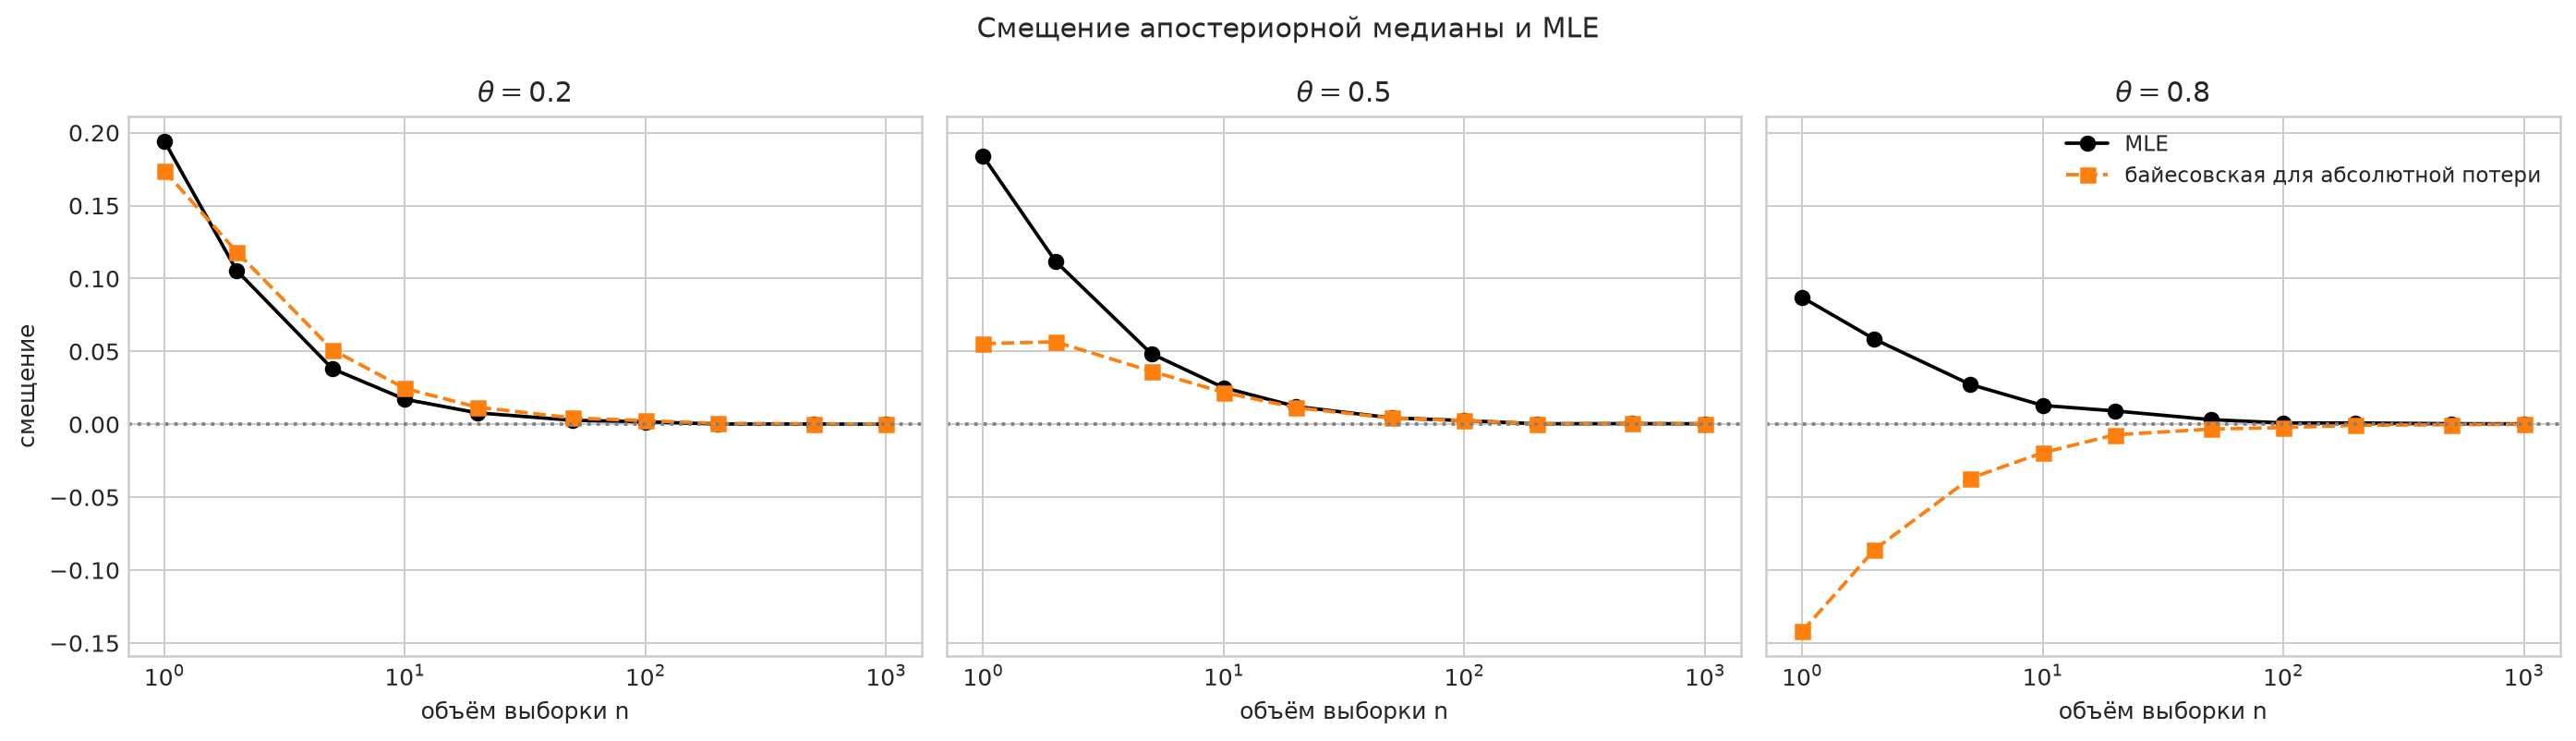

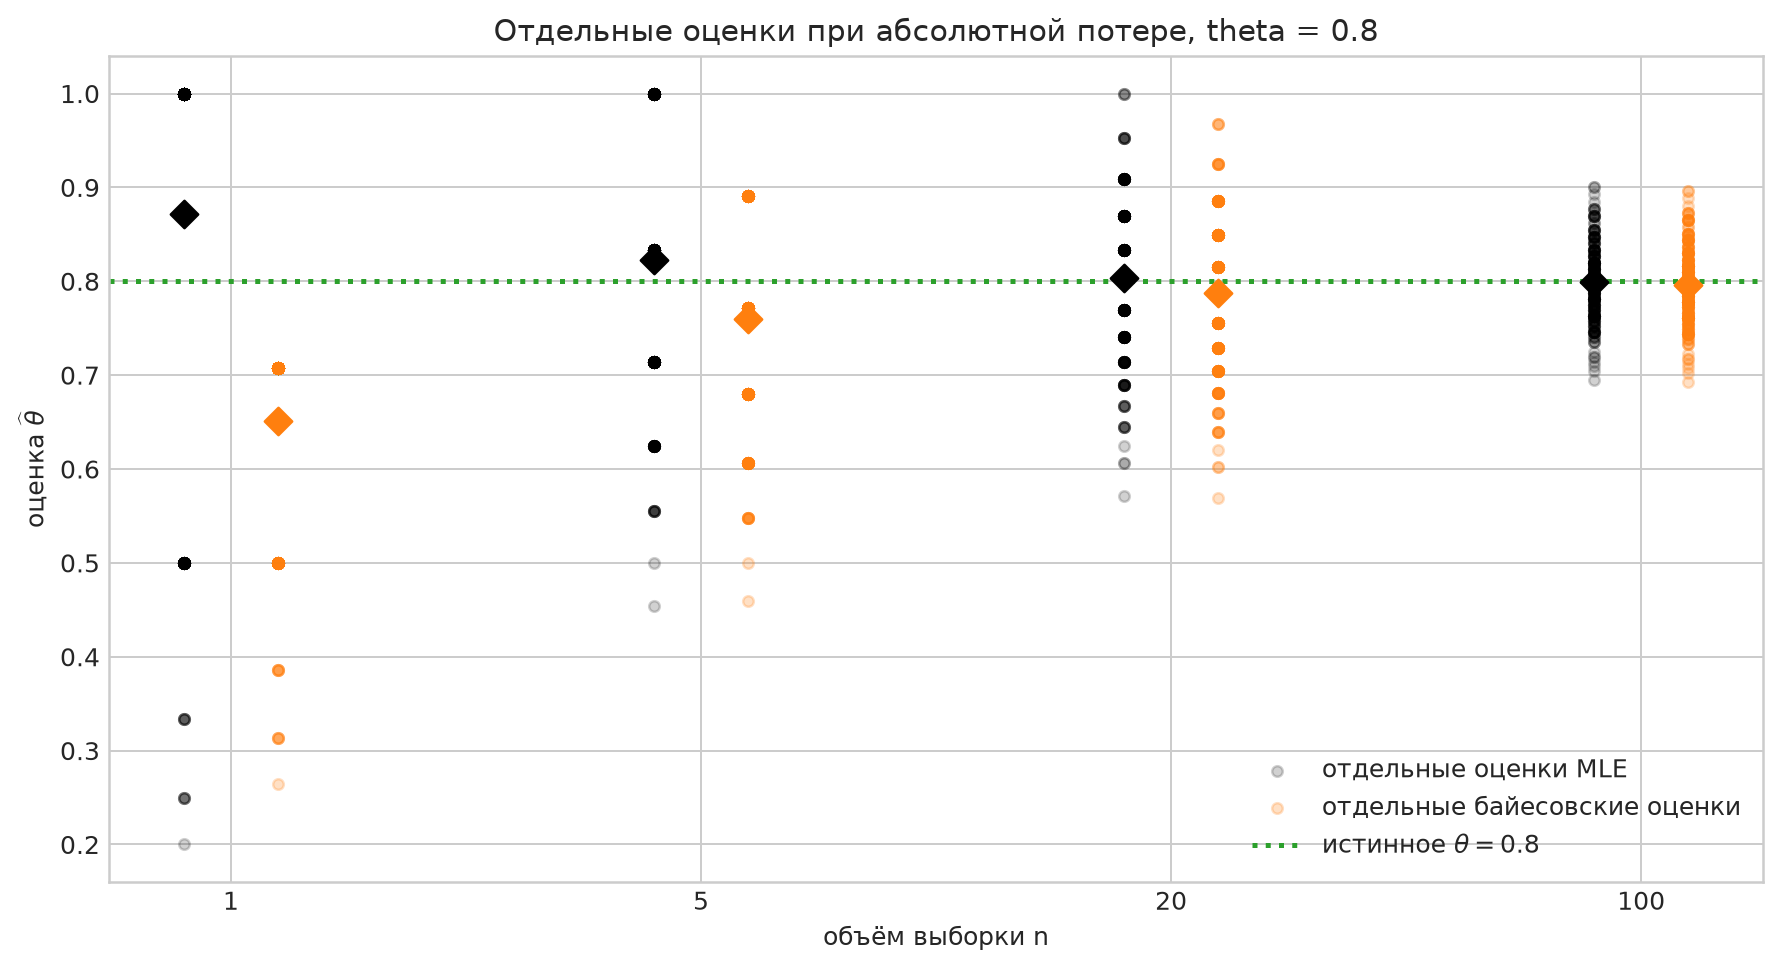

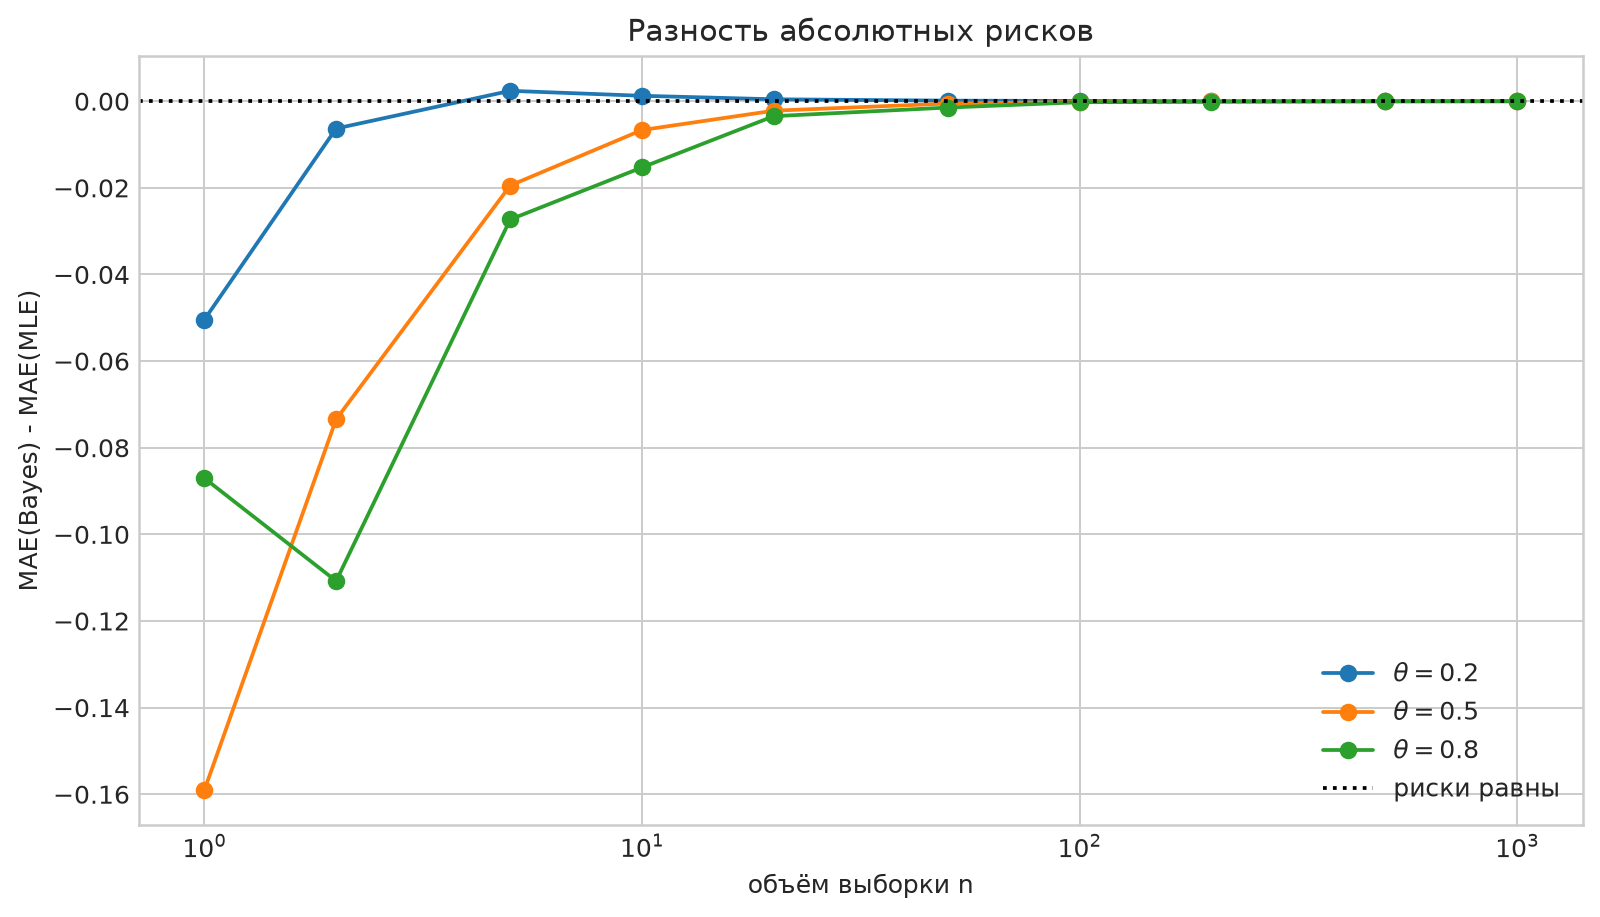

In [12]:
for theta in THETA_VALUES:
    print(f"theta = {theta:g}")
    for n in N:
        metrics = experiment["results"][float(theta)][int(n)]["metrics"]
        delta = metrics["absolute"]["mae"] - metrics["mle"]["mae"]
        print(f"n = {n:4d}: ΔMAE = {delta:+.8f}")
    print()

images = [
    save_metric_plot(
        experiment,
        "absolute",
        "mae",
        "MAE",
        "Абсолютный риск: апостериорная медиана и MLE",
        "mae.png",
        OUTPUT_DIR,
    ),
    save_bias_plot(
        experiment,
        "absolute",
        "Смещение апостериорной медианы и MLE",
        "absolute_bias.png",
        OUTPUT_DIR,
    ),
    save_estimate_cloud_plot(
        experiment,
        0.8,
        CLOUD_N,
        "absolute",
        "Отдельные оценки при абсолютной потере, theta = 0.8",
        "absolute_cloud.png",
        OUTPUT_DIR,
    ),
    save_risk_difference_plot(
        experiment,
        "absolute",
        "mae",
        "MAE(Bayes) - MAE(MLE)",
        "Разность абсолютных рисков",
        "absolute_risk_difference.png",
        OUTPUT_DIR,
    ),
]

for image in images:
    display(Image(filename=str(image)))

### Вывод по абсолютной потере

Апостериорная медиана при малых объёмах выборки также сглаживает крайние значения MLE. Это хорошо видно по облакам отдельных оценок: байесовские точки обычно занимают более узкий диапазон.

В эксперименте при $\theta=0.2$ апостериорная медиана выигрывает по MAE для $n=1$ и $n=2$, а начиная с $n=5$ небольшой выигрыш получает MLE. При $\theta=0.5$ и $\theta=0.8$ MAE апостериорной медианы меньше на всех рассмотренных объёмах. Как и для MSE, это сравнение проведено в отдельных фиксированных точках параметра.

При росте $n$ апостериорная медиана и MLE сближаются, их MAE убывают, а разность рисков стремится к нулю.

## Сравнение при 0–1 потере

В эксперименте используем предельную непрерывную интерпретацию 0–1 потери, то есть MAP-оценку, а качество измеряем конечным допуском

$$\widehat R_{0-1,\varepsilon}
=\frac1M\sum_{j=1}^{M}
\mathbb{1}(|\widehat\theta_j-\theta|>0.05)$$

При $a=b=1$ MAP и MLE совпадают на каждой выборке, а не только в среднем. Поэтому их эмпирические риски и число превышений должны совпасть точно.

На графике с отдельными оценками красные прямые задают допустимую полосу

$$[\theta-0.05,\theta+0.05]$$

Число над каждой группой точек показывает, сколько из всех $M=5000$ оценок вышли за эту полосу. Точки на графике являются только небольшой частью реализаций, а подписанное число вычисляется по всем повторениям.

theta = 0.2
n =    1: превышений = 3745
n =    2: превышений = 3383
n =    5: превышений = 2571
n =   10: превышений = 1806
n =   20: превышений = 1043
n =   50: превышений =  280
n =  100: превышений =   45
n =  200: превышений =    1
n =  500: превышений =    0
n = 1000: превышений =    0

theta = 0.5
n =    1: превышений = 3782
n =    2: превышений = 4052
n =    5: превышений = 3886
n =   10: превышений = 3401
n =   20: превышений = 2656
n =   50: превышений = 1483
n =  100: превышений =  737
n =  200: превышений =  221
n =  500: превышений =   15
n = 1000: превышений =    0

theta = 0.8
n =    1: превышений = 5000
n =    2: превышений = 5000
n =    5: превышений = 3341
n =   10: превышений = 2916
n =   20: превышений = 2753
n =   50: превышений = 1555
n =  100: превышений =  762
n =  200: превышений =  282
n =  500: превышений =   12
n = 1000: превышений =    0

Максимальная разность между MAP и MLE: 0.0


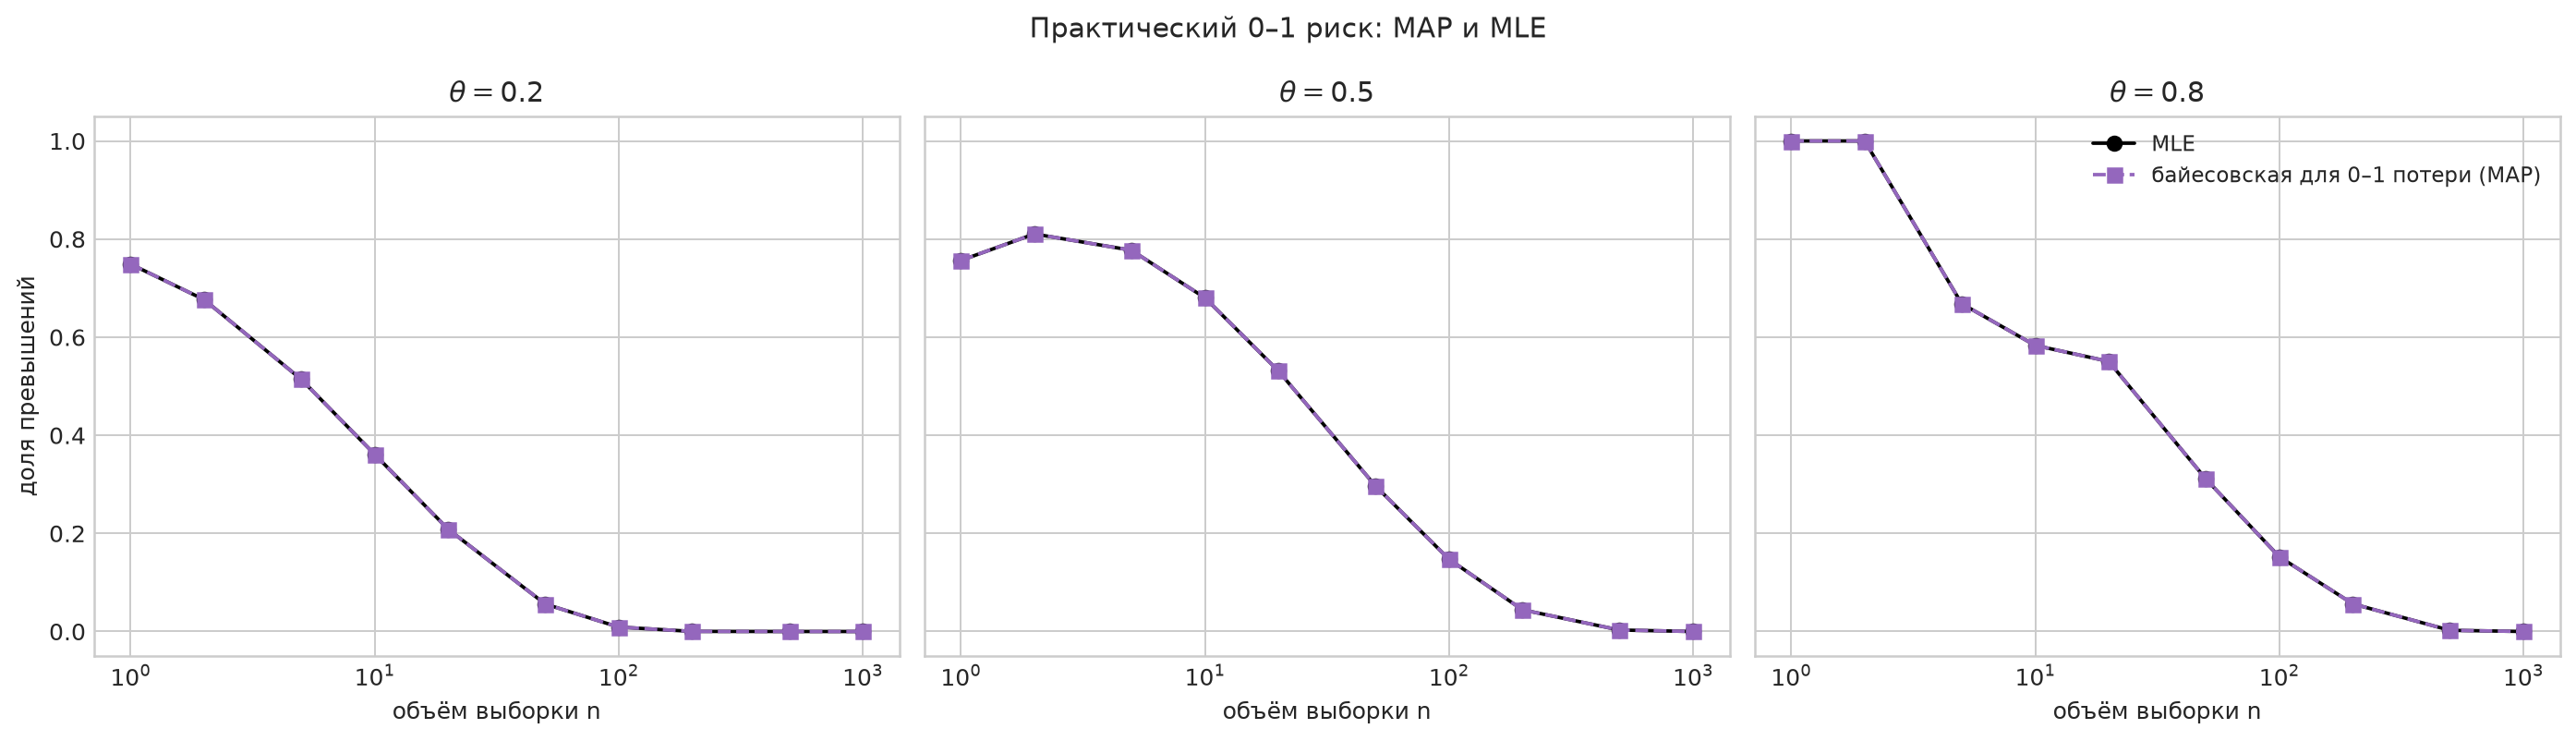

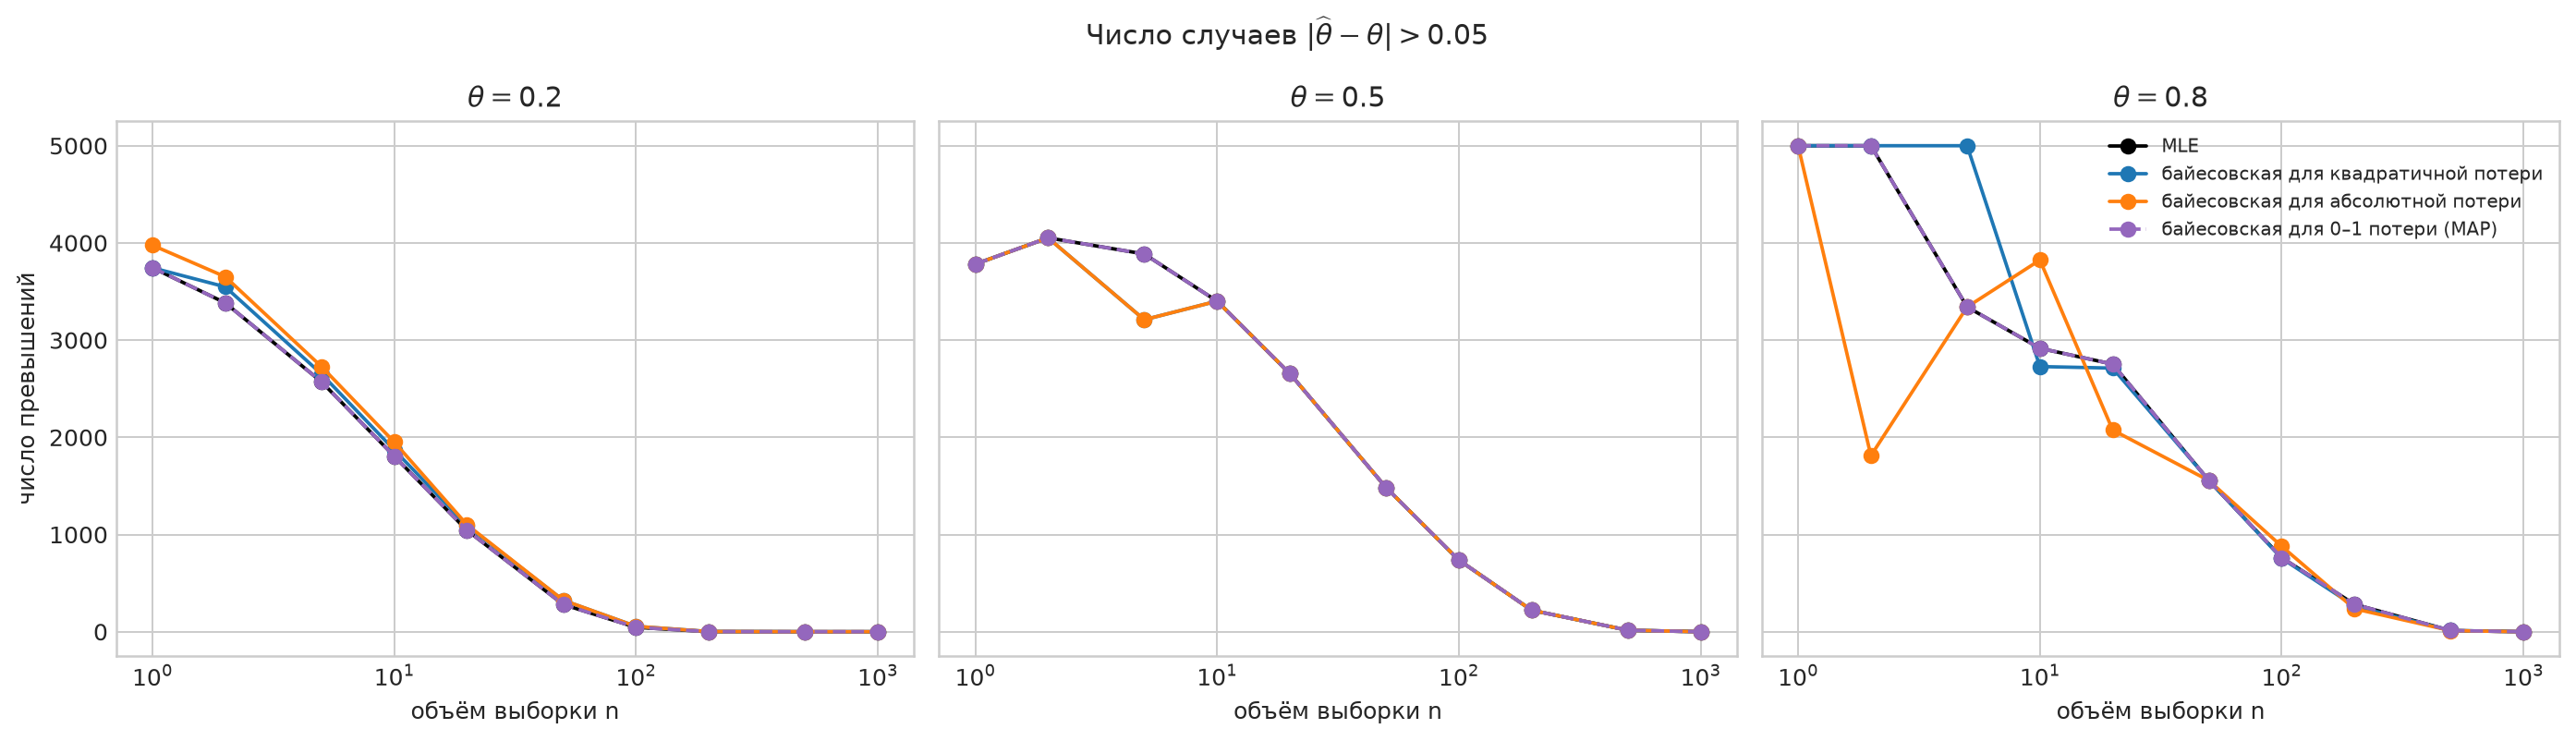

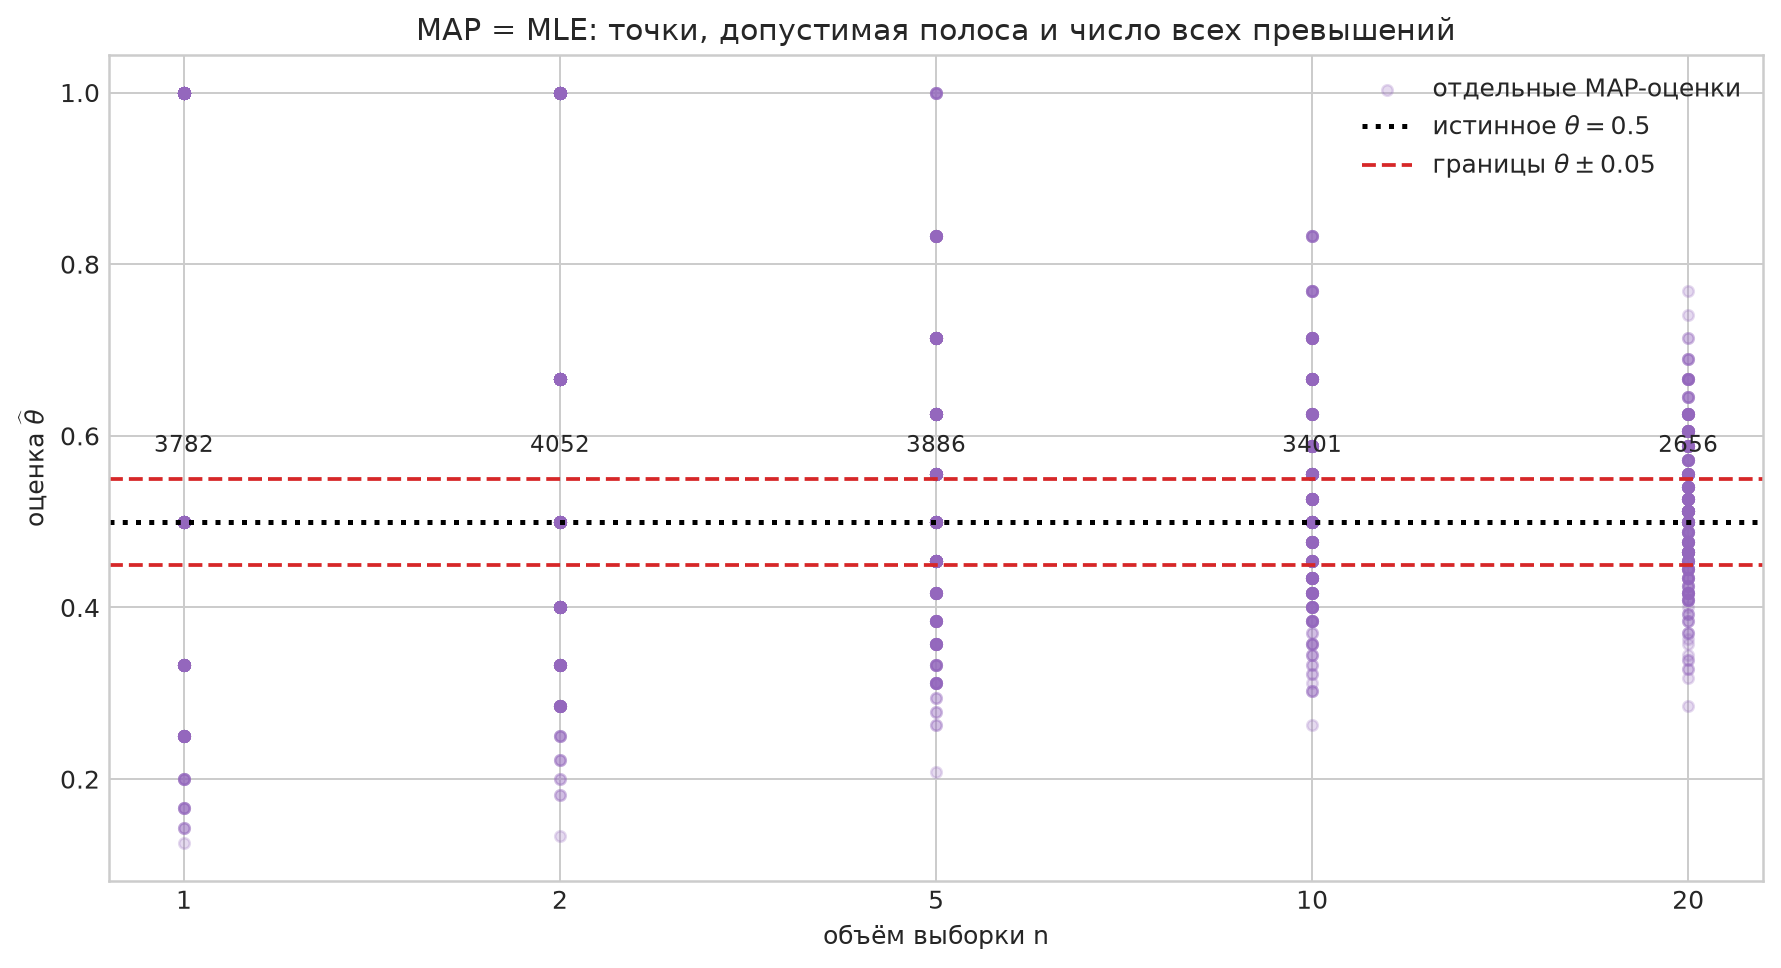

In [13]:
max_difference = 0.0
for theta in THETA_VALUES:
    print(f"theta = {theta:g}")
    for n in N:
        current = experiment["results"][float(theta)][int(n)]
        mle = current["estimates"]["mle"]
        map_estimates = current["estimates"]["zero_one"]
        difference = np.max(np.abs(map_estimates - mle))
        max_difference = max(max_difference, difference)

        count = current["metrics"]["zero_one"]["exceedances"]
        print(f"n = {n:4d}: превышений = {count:4d}")
    print()

print(f"Максимальная разность между MAP и MLE: {max_difference:.1f}")

images = [
    save_metric_plot(
        experiment,
        "zero_one",
        "zero_one",
        "доля превышений",
        "Практический 0–1 риск: MAP и MLE",
        "epsilon_zero_one_risk.png",
        OUTPUT_DIR,
    ),
    save_threshold_counts_plot(
        experiment,
        OUTPUT_DIR,
    ),
    save_threshold_cloud_plot(
        experiment,
        0.5,
        THRESHOLD_N,
        OUTPUT_DIR,
    ),
]

for image in images:
    display(Image(filename=str(image)))

### Вывод по 0–1 потере

Численное равенство MAP и MLE подтверждает теоретическое тождество для $a=b=1$. Их линии на графиках полностью накладываются друг на друга, а максимальная разность между оценками равна нулю.

В целом при росте $n$ оценки концентрируются около истинного параметра, поэтому доля и абсолютное число выходов за полосу $\theta\pm0.05$ уменьшаются. На самых малых объёмах убывание не обязано быть монотонным. Оценка $n/(n+S)$ принимает дискретный набор значений, и при изменении $n$ часть этого набора может попадать в фиксированную полосу или выходить из неё. Например, при $\theta=0.5$ число превышений для $n=2$ получилось больше, чем для $n=1$. На больших выборках закон больших чисел стабилизирует $S/n$, дискретная сетка становится плотнее и практический 0–1 риск приближается к нулю.

## Итоговое сравнение критериев

На последнем рисунке все четыре оценки сравниваются на одних данных при $\theta=0.5$ сразу по трём критериям. Каждый столбец отвечает своей функции потерь:

- MSE соответствует квадратичной потере
- MAE соответствует абсолютной потере
- вероятность превышения соответствует практической $\varepsilon$-версии 0–1 потери

Оценка, являющаяся байесовской для одной функции потерь, не обязана быть лучшей по другой функции. Поэтому три панели следует рассматривать отдельно.

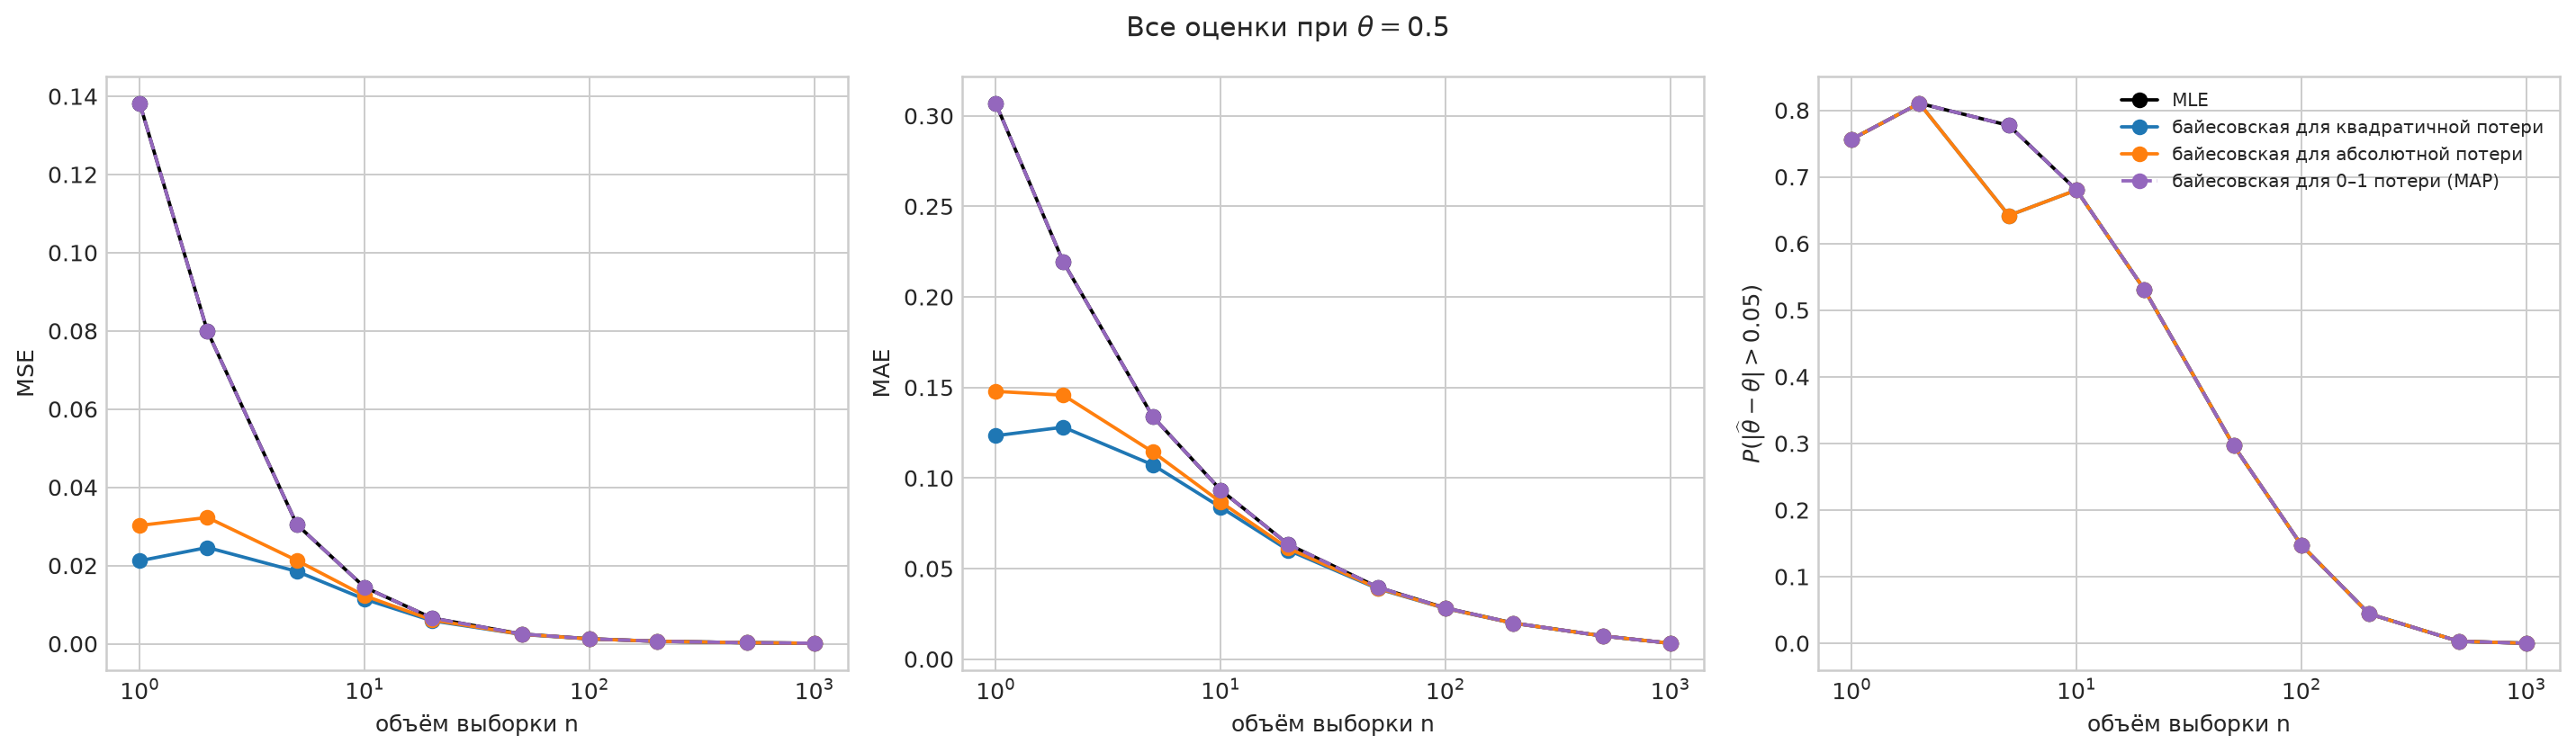

In [14]:
image = save_all_metrics_plot(
    experiment,
    theta=0.5,
    output_dir=OUTPUT_DIR,
)
display(Image(filename=str(image)))

## Выводы

Для геометрической модели

$$p_\theta(x)=\theta(1-\theta)^x$$

с бета-приором

$$\theta\sim\operatorname{Beta}(a,b)$$

апостериорное распределение также является бета-распределением:

$$\boxed{\theta\mid X_1,\ldots,X_n
\sim\operatorname{Beta}(a+n,b+S)}$$

Оценка максимального правдоподобия равна

$$\boxed{\widehat\theta_{\mathrm{MLE}}=\frac n{n+S}}$$

Для трёх функций потерь получены байесовские оценки

$$\boxed{
\widehat\theta_{L_2}
=\frac{a+n}{a+b+n+S}
}$$

$$\boxed{
\widehat\theta_{L_1}
=F^{-1}_{\operatorname{Beta}(a+n,b+S)}\left(\frac12\right)
}$$

$$\boxed{
\widehat\theta_{0-1}
=\widehat\theta_{\mathrm{MAP}}
=\frac{a+n-1}{a+b+n+S-2}
}$$

Последняя формула относится к внутренней моде и понимается как предел непрерывной $\varepsilon$-версии 0–1 потери.

При заданных в условии $a=b=1$

$$\widehat\theta_{\mathrm{MAP}}
=\widehat\theta_{\mathrm{MLE}}$$

Апостериорное среднее и медиана при малых $n$ сглаживают MLE и стягивают оценку к центру равномерного приора $1/2$. Это уменьшает разброс, но при $\theta\ne1/2$ создаёт направленное смещение. С ростом $n$ влияние приора исчезает, все оценки сходятся к истинному параметру, а MSE, MAE и практический 0–1 риск убывают.

Для буквальной 0–1 потери непрерывного параметра любая оценка имеет максимальный риск 1, поэтому любая оценка минимаксна. При любом $a,b>0$ апостериорное распределение непрерывно и любая оценка одновременно является байесовской. В содержательной предельной интерпретации MAP совпадает с MLE для всех выборок тогда и только тогда, когда

$$\boxed{a=b=1}$$